# Detecção de anomalias em dados da correia transportadora da Vale

O notebook processa sinais de aceleração, seleciona os trechos de interesse, extrai
características espectrais por janela e treina modelos K-Means para detecção de anomalias.

## Configuração e pré-processamento

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import glob
import os
import joblib
import math
import scipy
import scipy.signal
from mpl_toolkits.mplot3d import Axes3D
from scipy.fft import fft, fftfreq
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, f1_score, classification_report, confusion_matrix
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from scipy.spatial.distance import cdist


CAMINHO_ALINHADO = "C:/Users/Raiza/Downloads/convenyor_belt_verlab/arquivos/logs/logs_vale/Alinhado/*.csv"
CAMINHO_ANOMALIA = "C:/Users/Raiza/Downloads/material_raiza/material_raiza/experimento_09_04_25_LLK/Realinhamendo_direita_em_funcionamento/*.csv"

FS = 50
N_JANELA = 64
STEP = 16
EIXOS = ['x_data_processed', 'y_data_processed', 'z_data_processed']
EIXOS_RAW = ['x_data', 'y_data', 'z_data']

RANGE_ACC = 16
RANGE_GYRO = 2000
CONVERSION_FACTOR_ACC = ((2 * RANGE_ACC) / (2**15)) * 9.81
CONVERSION_FACTOR_GYRO = (2 * RANGE_GYRO) / (2**15)
DT = 0.02
half_window = 25
COMPARISON_CONF_INT = 0.95

np.random.seed(5)


C:\Users\Raiza\AppData\Roaming\Python\Python311\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\Raiza\AppData\Roaming\Python\Python311\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


In [2]:
def configurar_colunas(df):
    """Renomeia as colunas do CSV para corrigir o mapeamento dos eixos do sensor."""
    df = df.rename(columns={
            'x_data': 'x_data',
            'y_data': 'x_gyro',
            'z_data': 'y_data',
            'x_gyro': 'y_gyro',
            'y_gyro': 'z_data',
            'z_gyro': 'z_gyro'

        })
    return df


In [3]:
def filter_signal(data, cutoff, order, dt):
    """
    Aplica um filtro Butterworth passa-baixa ao sinal usando o intervalo de amostragem
    informado.
    """
    fs = 1 / dt
    lowpass_filter = scipy.signal.butter(order, cutoff, btype='lowpass', fs=fs, output='sos')
    filtered_signal = scipy.signal.sosfilt(lowpass_filter, data)
    return filtered_signal


def correct_gravity_dynamically(data):
    """
    Converte a aceleração para m/s², estima a gravidade pela magnitude filtrada e remove sua
    projeção de cada eixo.
    """

    acc_x = np.array(data['x_data'], dtype=float) * CONVERSION_FACTOR_ACC
    acc_y = np.array(data['y_data'], dtype=float) * CONVERSION_FACTOR_ACC
    acc_z = np.array(data['z_data'], dtype=float) * CONVERSION_FACTOR_ACC


    acc_magnitude = np.sqrt(acc_x**2 + acc_y**2 + acc_z**2)


    gravity_magnitude = filter_signal(acc_magnitude, cutoff=1, order=4, dt=DT)


    gravity_x = (acc_x / acc_magnitude) * gravity_magnitude
    gravity_y = (acc_y / acc_magnitude) * gravity_magnitude
    gravity_z = (acc_z / acc_magnitude) * gravity_magnitude


    acc_x_corrected = acc_x - gravity_x
    acc_y_corrected = acc_y - gravity_y
    acc_z_corrected = acc_z - gravity_z

    return acc_x_corrected, acc_y_corrected, acc_z_corrected


def preprocess_dataframe(df):
    """
    Gera os três eixos processados usados pelo modelo após correção da gravidade e remoção
    da componente constante.
    """

    acc_x_corr, acc_y_corr, acc_z_corr = correct_gravity_dynamically(df)


    df['x_data_processed'] = scipy.signal.detrend(acc_x_corr, type='constant')
    df['y_data_processed'] = scipy.signal.detrend(acc_y_corr, type='constant')
    df['z_data_processed'] = scipy.signal.detrend(acc_z_corr, type='constant')

    return df


In [4]:
def plot_all_files(arquivos, lista_df):
    """Plota os eixos processados de todas as coletas em uma grade para inspeção visual."""
    n_arquivos = len(lista_df)
    n_cols = 3
    n_rows = math.ceil(n_arquivos / n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 3 * n_rows))

    if n_arquivos > 1:
        axes_flat = axes.flatten()
    else:
        axes_flat = [axes]

    for i, (arquivo, df) in enumerate(zip(arquivos, lista_df)):
        ax = axes_flat[i]
        nome_arquivo = os.path.basename(arquivo)

        try:
            colunas_plot = [col for col in EIXOS if col in df.columns]

            if colunas_plot:
                df[colunas_plot].plot(ax=ax, linewidth=0.8, alpha=0.8)
                ax.set_title(nome_arquivo, fontsize=9)
                ax.legend(fontsize=7, loc='upper right')
                ax.tick_params(axis='both', which='major', labelsize=7)
            else:
                ax.set_title(f"Colunas ausentes em:\n{nome_arquivo}", fontsize=9)

        except Exception as e:
            ax.set_title(f"Erro ao ler:\n{nome_arquivo}", fontsize=9)

    for j in range(n_arquivos, len(axes_flat)):
        fig.delaxes(axes_flat[j])
    plt.tight_layout()
    plt.show()


In [5]:
def extract_z_positive_data_teste(df):
    """Demonstra, com mensagens de diagnóstico, a seleção regressiva do trecho positivo de z."""
    last_row_positive = False
    end_positive = False
    z_positive = []
    for row in reversed(df.z_data):
        if row < 0 and last_row_positive is True:
            end_positive = True
        if row >= 0 and end_positive is False:
            last_row_positive = True
            z_positive.insert(0, True)
            print(f"row:{row} last_row_positive:{last_row_positive} end_positive:{end_positive}")
        else:
            last_row_positive = False
            z_positive.insert(0, False)
            print(f"row:{row} last_row_positive:{last_row_positive} end_positive:{end_positive}")

    print(f"z_positive:{z_positive}")
    return df[z_positive]


In [6]:
df_teste = pd.DataFrame({"z_data": [-1,-2,-3, 1, 3, 2, 4, -1, -2], "col2": [1, 2, 3, 12, 3, 2, 4, 1, 2]})
print(df_teste)
df_teste = extract_z_positive_data_teste(df_teste)
print(df_teste)


   z_data  col2
0      -1     1
1      -2     2
2      -3     3
3       1    12
4       3     3
5       2     2
6       4     4
7      -1     1
8      -2     2
row:-2 last_row_positive:False end_positive:False
row:-1 last_row_positive:False end_positive:False
row:4 last_row_positive:True end_positive:False
row:2 last_row_positive:True end_positive:False
row:3 last_row_positive:True end_positive:False
row:1 last_row_positive:True end_positive:False
row:-3 last_row_positive:False end_positive:True
row:-2 last_row_positive:False end_positive:True
row:-1 last_row_positive:False end_positive:True
z_positive:[False, False, False, True, True, True, True, False, False]
   z_data  col2
3       1    12
4       3     3
5       2     2
6       4     4


In [7]:
def extract_z_positive_data(df_list):
    """
    Recorta em cada coleta o trecho positivo final de z, encerrando após cinco valores
    negativos consecutivos e mantendo uma margem de dez amostras.
    """
    df_list_novo = []
    for df in df_list:
        started = False
        end_positive = False
        negativos_consecutivos = 0
        z_positive = []

        for row in reversed(df.z_data):
            if end_positive:
                z_positive.insert(0, False)
                continue

            if row >= 0:
                started = True
                negativos_consecutivos = 0
                z_positive.insert(0, True)
            else:
                if started:
                    negativos_consecutivos += 1
                    if negativos_consecutivos >= 5:
                        end_positive = True

                z_positive.insert(0, False)


        if True in z_positive:
            primeiro_true = z_positive.index(True)
            ultimo_true = len(z_positive) - 1 - z_positive[::-1].index(True)
            inicio = max(0, primeiro_true - 10)
            fim = min(len(df), ultimo_true + 11)

            df_cortado = df.iloc[inicio:fim].copy().reset_index(drop=True)
        else:
            df_cortado = df.iloc[0:0].copy().reset_index(drop=True)

        df_list_novo.append(df_cortado)

    return df_list_novo


## Carregamento, seleção e normalização das coletas

In [8]:
arquivos_alinhados = glob.glob(CAMINHO_ALINHADO)
lista_df_alinhado = []
for arquivo in arquivos_alinhados:
    df = pd.read_csv(arquivo)
    df = configurar_colunas(df)
    df = preprocess_dataframe(df)
    lista_df_alinhado.append(df)

print(f"{len(lista_df_alinhado)} arquivos.")
print(f"tam antes do tratamento: {len(lista_df_alinhado[1])}")

df_alinhado = pd.concat(lista_df_alinhado, ignore_index=True)
df_alinhado


11 arquivos.
tam antes do tratamento: 417


,x_data,x_gyro,y_data,y_gyro,z_data,z_gyro,temp,x_data_processed,y_data_processed,z_data_processed
0,-424,-13,-173,-19,880,6,202,-4.004719,-1.639706,8.315464
1,-425,0,-174,-9,880,6,206,-4.013884,-1.649116,8.314604
2,-427,0,-172,-11,882,6,204,-4.031465,-1.629323,8.330505
3,-426,0,-172,-9,883,5,204,-4.017828,-1.627683,8.331662
4,-425,-3,-172,-8,883,5,200,-4.000029,-1.624351,8.314557
...,...,...,...,...,...,...,...,...,...,...
6225,108,59,-79,153,-1162,19,498,0.048681,-0.071906,-0.173609
6226,132,-85,16,313,-1442,19,498,0.291501,0.029425,-2.840142
6227,35,117,-138,27,-1198,19,498,0.001476,-0.156564,-0.536760
6228,50,141,-169,-161,-1280,5,496,0.045745,-0.285301,-1.349794


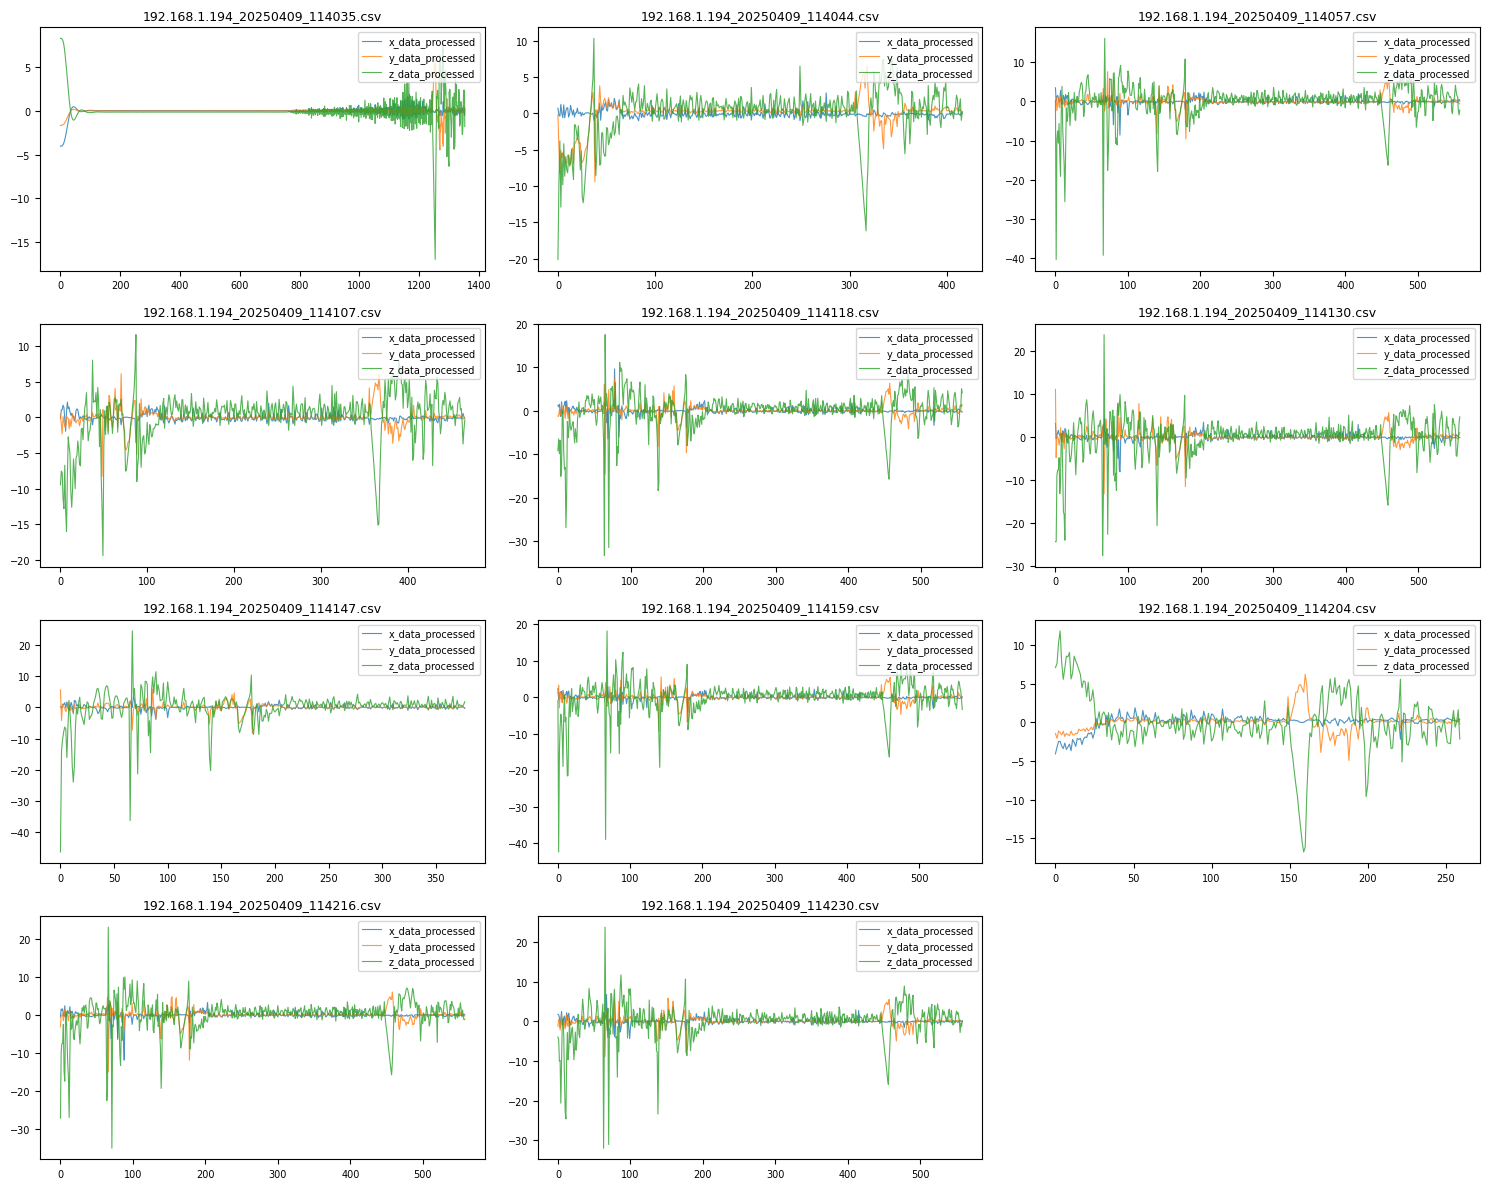

In [9]:
plot_all_files(arquivos_alinhados, lista_df_alinhado)


In [10]:
lista_df_alinhado[0].columns


Index(['x_data', 'x_gyro', 'y_data', 'y_gyro', 'z_data', 'z_gyro', 'temp',
       'x_data_processed', 'y_data_processed', 'z_data_processed'],
      dtype='str')

In [11]:
indices_remover = [0, 6, 8]
lista_df_alinhado = [df for i, df in enumerate(lista_df_alinhado) if i not in indices_remover]
arquivos_alinhados = [arq for i, arq in enumerate(arquivos_alinhados) if i not in indices_remover]

print(f"{len(lista_df_alinhado)} arquivos.")

lista_df_alinhado = extract_z_positive_data(lista_df_alinhado)

print(f"tam depois do tratamento: {len(lista_df_alinhado[0])}")

df_alinhado = pd.concat(lista_df_alinhado, ignore_index=True)
df_alinhado


8 arquivos.
tam depois do tratamento: 289


,x_data,x_gyro,y_data,y_gyro,z_data,z_gyro,temp,x_data_processed,y_data_processed,z_data_processed
0,26,8119,-1048,237,-1851,39,280,0.043349,-5.108099,-8.842104
1,29,8055,-1100,222,-1661,31,284,0.043590,-4.793396,-6.959536
2,48,8071,-1169,225,-1469,26,284,0.106747,-4.478106,-5.251362
3,52,8095,-1114,226,-1295,35,282,0.081390,-3.349637,-3.481702
4,52,8166,-1073,225,-1181,42,278,0.043612,-2.432653,-2.241546
...,...,...,...,...,...,...,...,...,...,...
2303,-34,9801,852,306,-1782,56,492,-0.198530,4.071646,-7.803837
2304,-22,9794,830,308,-1955,48,500,-0.148372,4.242914,-9.284339
2305,-41,9703,831,307,-2164,49,496,-0.260872,4.554877,-11.154346
2306,-23,9639,825,305,-2361,58,496,-0.168651,4.760875,-12.920424


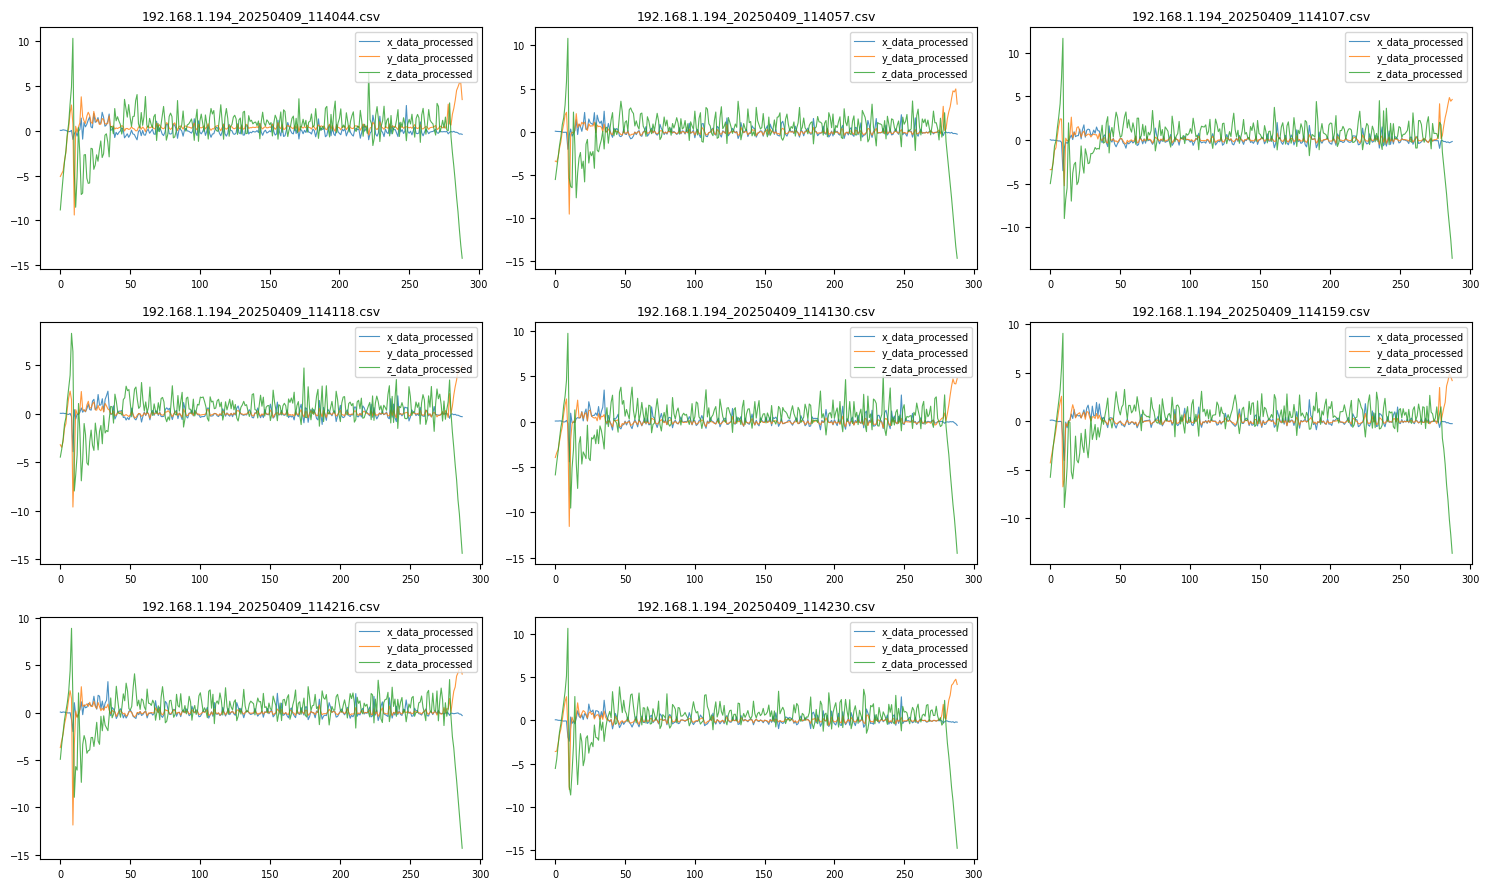

In [12]:
plot_all_files(arquivos_alinhados, lista_df_alinhado)


In [13]:
colunas_para_normalizar = EIXOS
scaler = StandardScaler()


scaler.fit(df_alinhado[colunas_para_normalizar])


for df in lista_df_alinhado:
    df[colunas_para_normalizar] = scaler.transform(df[colunas_para_normalizar])


11 arquivos.


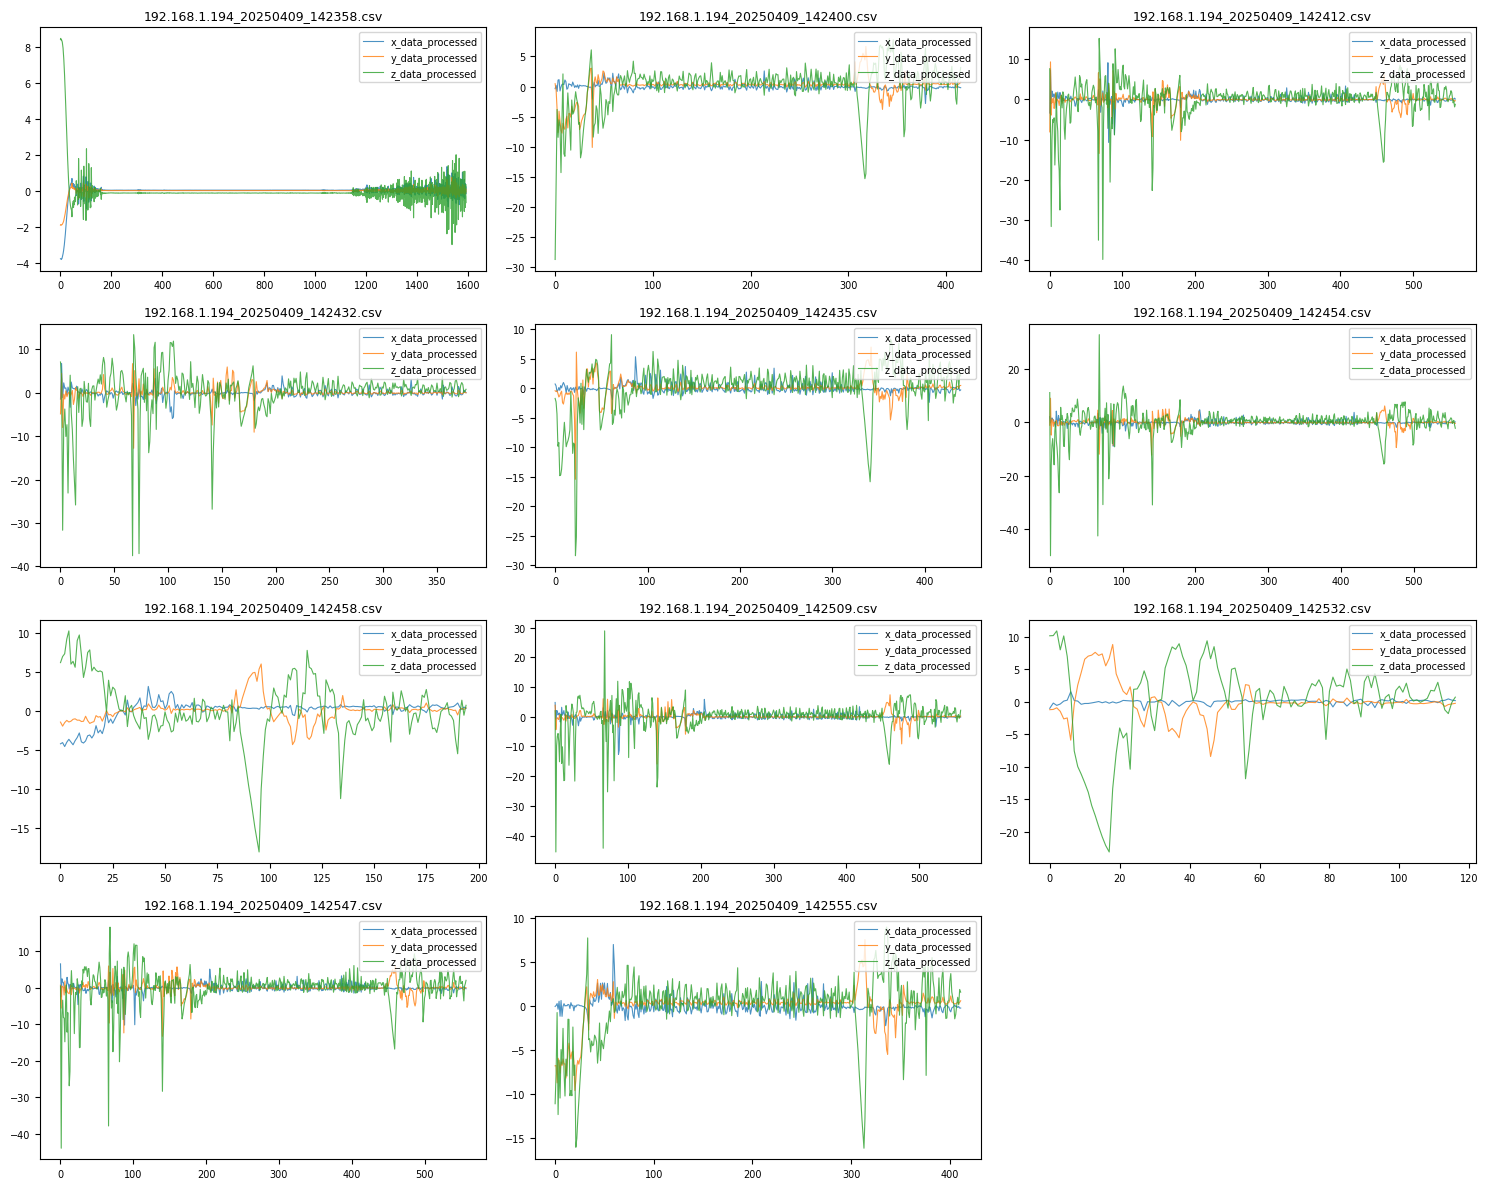

In [14]:
arquivos_desalinhamento_dir = glob.glob("C:/Users/Raiza/Downloads/material_raiza/material_raiza/experimento_09_04_25_LLK/Desalinhamento_direita_em_funcionamento/*.csv")
lista_df_desalinhamento_dir = []
for arquivo in arquivos_desalinhamento_dir:
    df = pd.read_csv(arquivo)
    df = configurar_colunas(df)
    df = preprocess_dataframe(df)
    lista_df_desalinhamento_dir.append(df)

print(f"{len(lista_df_desalinhamento_dir)} arquivos.")

plot_all_files(arquivos_desalinhamento_dir, lista_df_desalinhamento_dir)


7 arquivos.


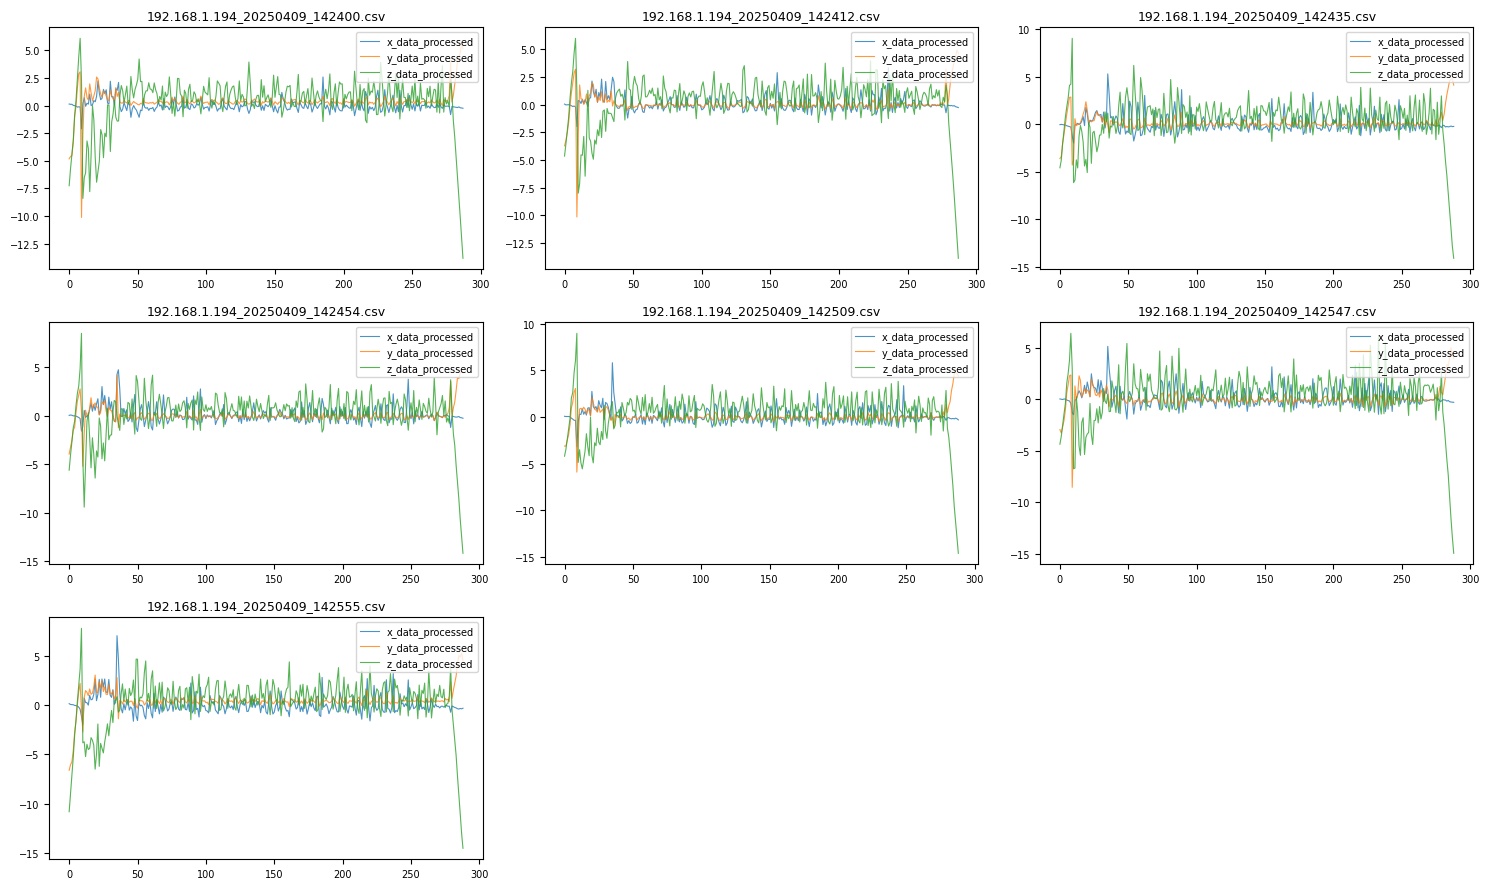

In [15]:
indices_remover = [0, 3, 6, 8]
lista_df_desalinhamento_dir = [df for i, df in enumerate(lista_df_desalinhamento_dir) if i not in indices_remover]
arquivos_desalinhamento_dir = [arq for i, arq in enumerate(arquivos_desalinhamento_dir) if i not in indices_remover]

print(f"{len(lista_df_desalinhamento_dir)} arquivos.")

lista_df_desalinhamento_dir = extract_z_positive_data(lista_df_desalinhamento_dir)

df_desalinhamento_dir = pd.concat(lista_df_desalinhamento_dir, ignore_index=True)
plot_all_files(arquivos_desalinhamento_dir, lista_df_desalinhamento_dir)


In [16]:
for df in lista_df_desalinhamento_dir:
    df[colunas_para_normalizar] = scaler.transform(df[colunas_para_normalizar])


16 arquivos.


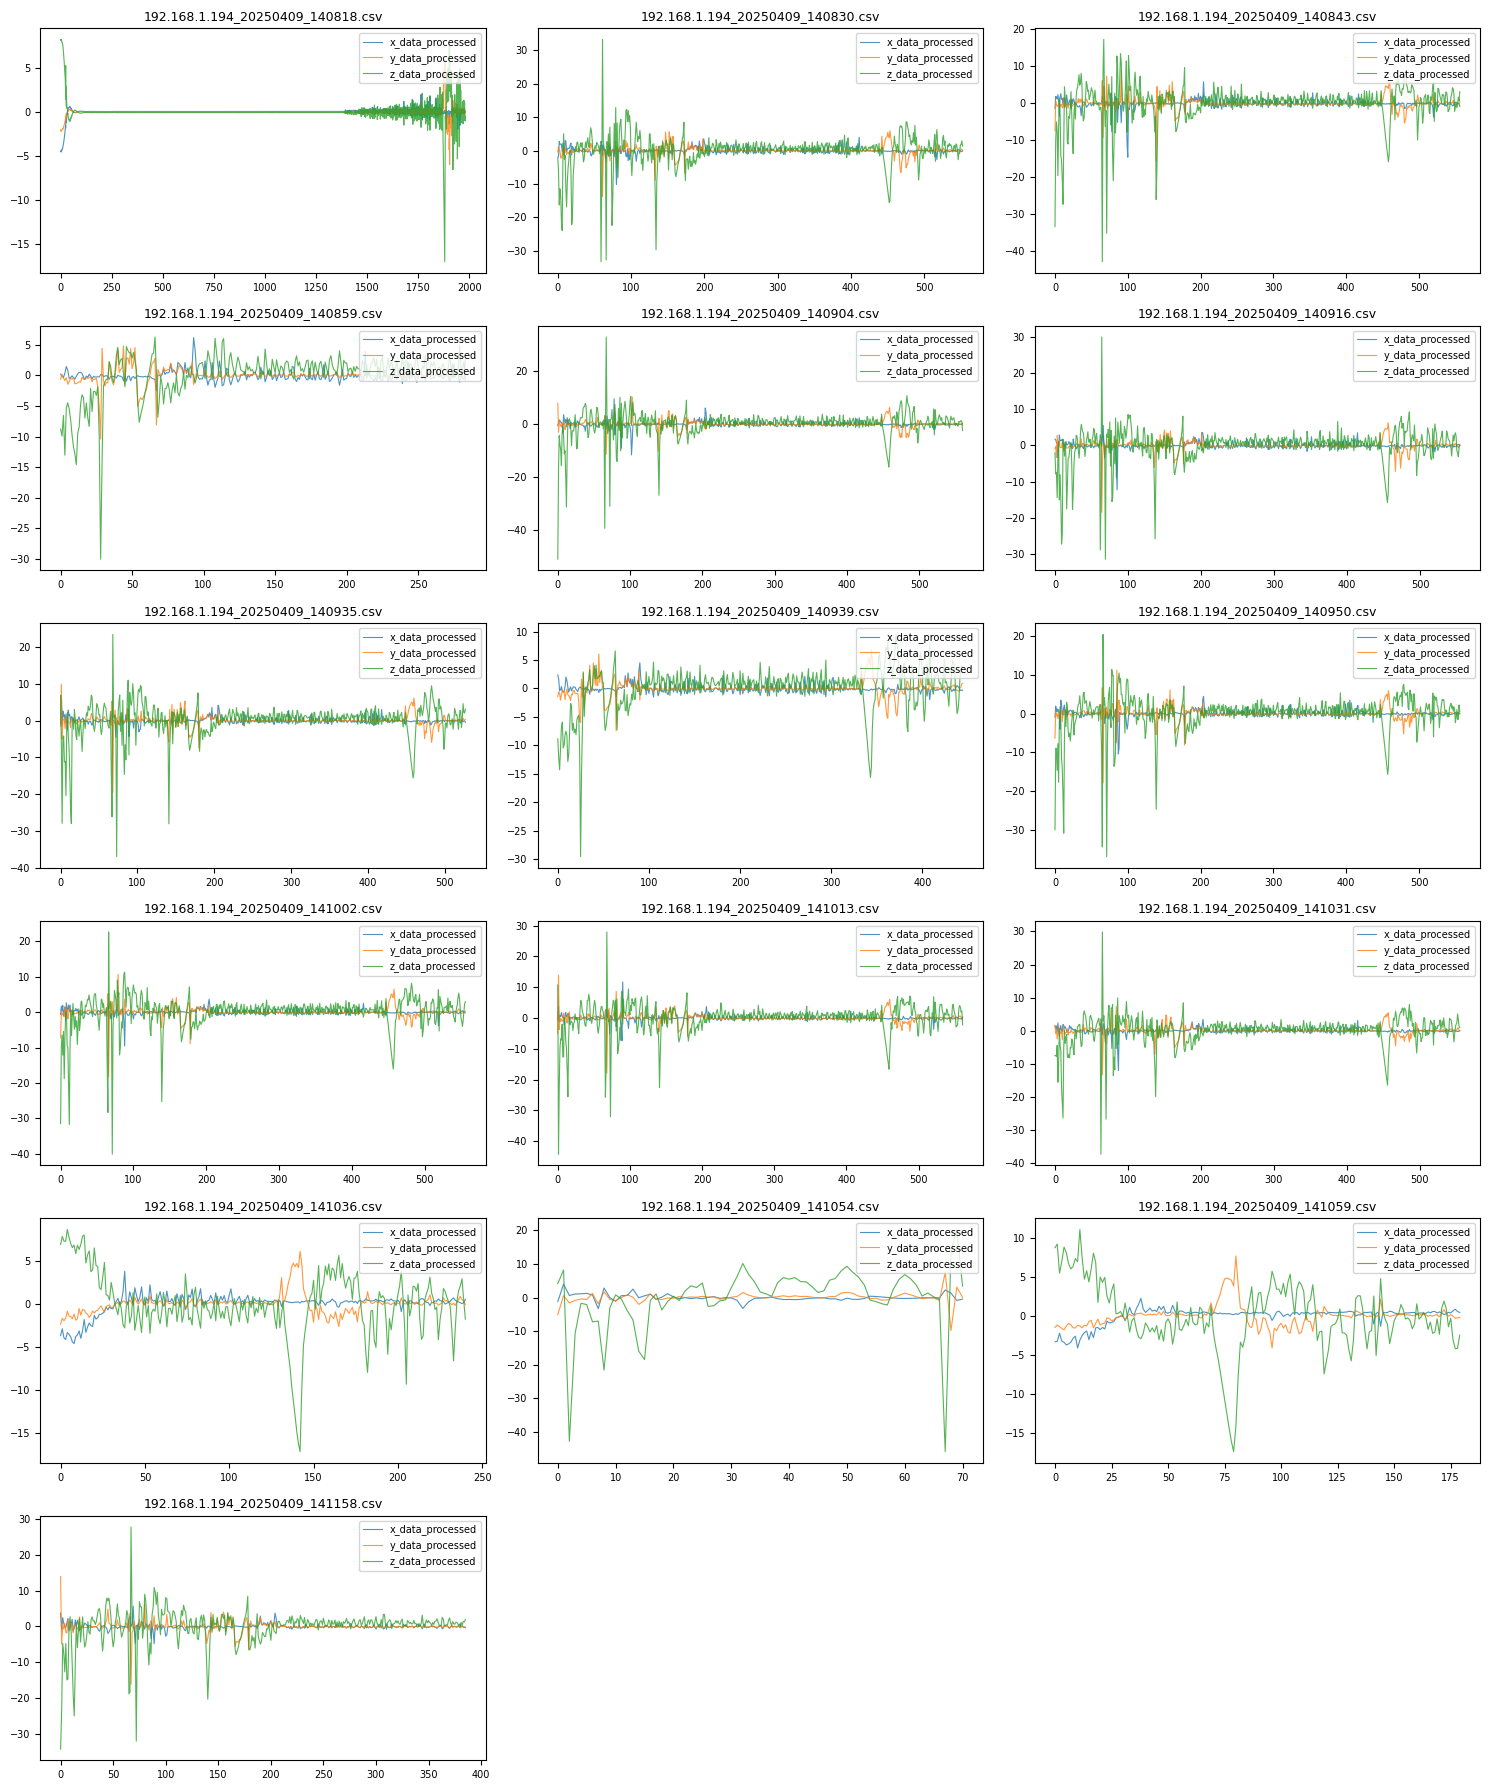

In [17]:
arquivos_realinhamento_dir = glob.glob("C:/Users/Raiza/Downloads/material_raiza/material_raiza/experimento_09_04_25_LLK/Realinhamendo_direita_em_funcionamento/*.csv")
lista_df_realinhamento_dir = []
for arquivo in arquivos_realinhamento_dir:
    df = pd.read_csv(arquivo)
    df = configurar_colunas(df)
    df = preprocess_dataframe(df)
    lista_df_realinhamento_dir.append(df)

print(f"{len(lista_df_realinhamento_dir)} arquivos.")

plot_all_files(arquivos_realinhamento_dir, lista_df_realinhamento_dir)


10 arquivos.


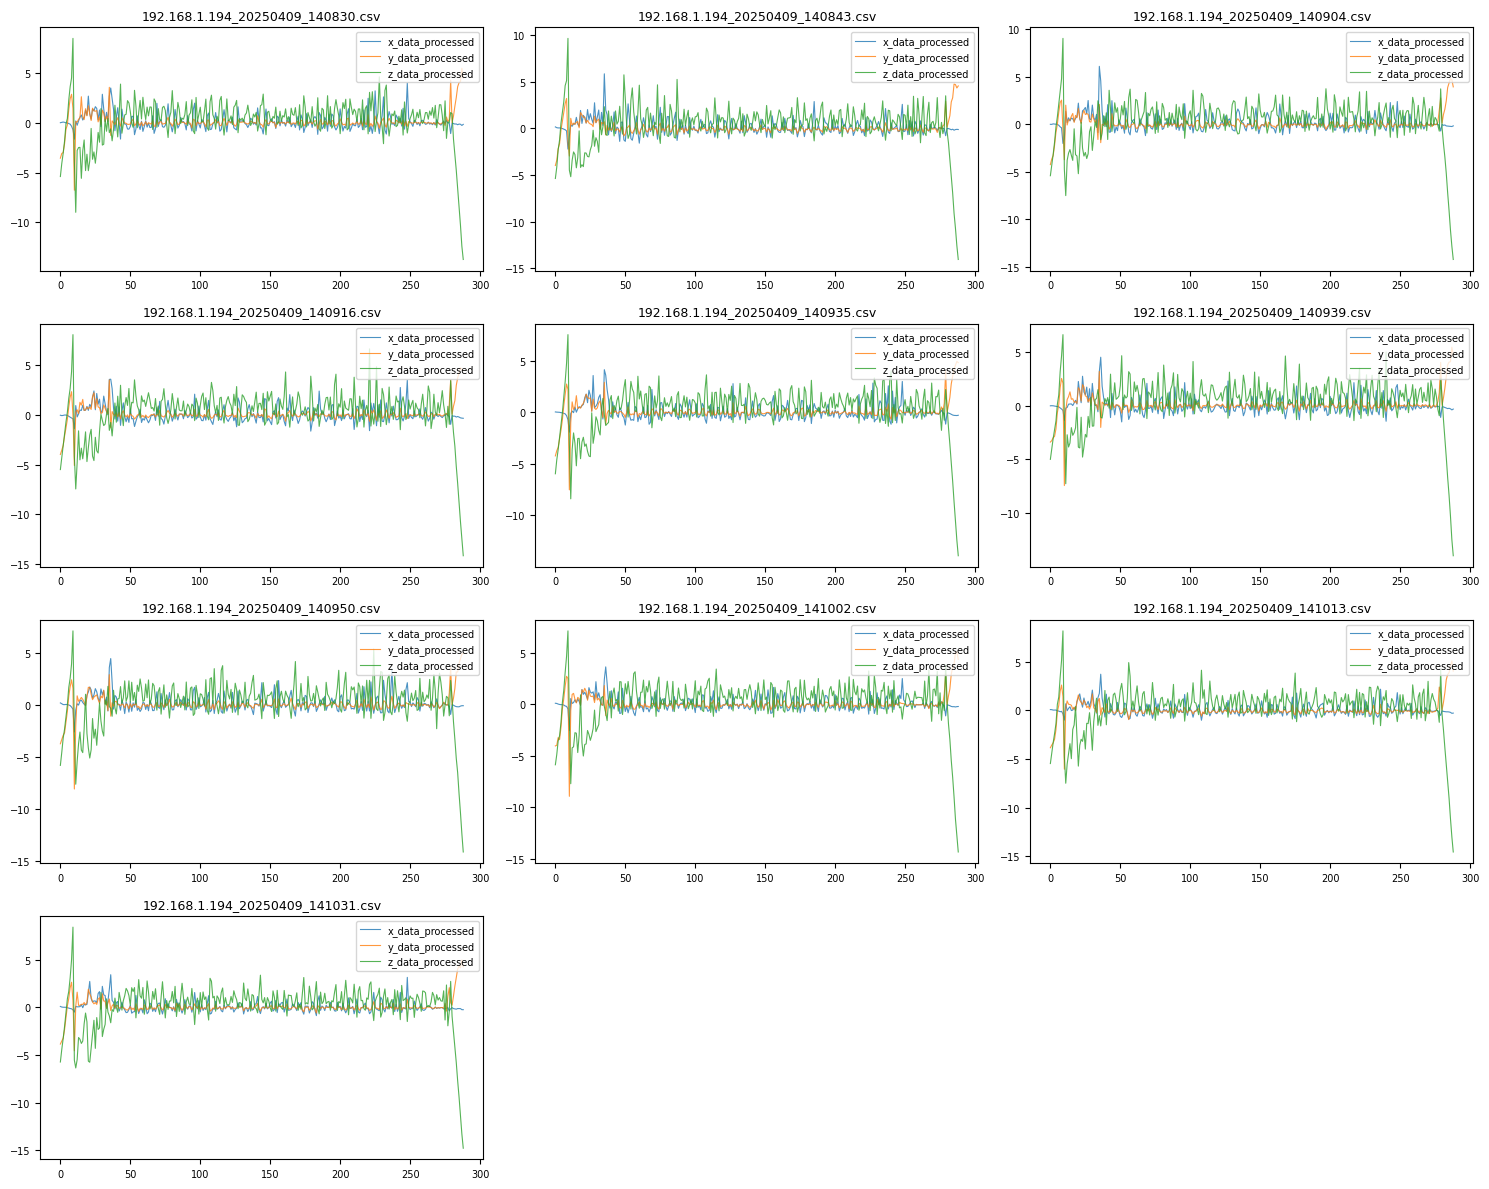

In [18]:
indices_remover = [0, 3, 12, 13, 14, 15]
lista_df_realinhamento_dir = [df for i, df in enumerate(lista_df_realinhamento_dir) if i not in indices_remover]
arquivos_realinhamento_dir = [arq for i, arq in enumerate(arquivos_realinhamento_dir) if i not in indices_remover]

print(f"{len(lista_df_realinhamento_dir)} arquivos.")

lista_df_realinhamento_dir = extract_z_positive_data(lista_df_realinhamento_dir)

df_realinhamento_dir = pd.concat(lista_df_realinhamento_dir, ignore_index=True)
plot_all_files(arquivos_realinhamento_dir, lista_df_realinhamento_dir)


In [19]:
for df in lista_df_realinhamento_dir:
    df[colunas_para_normalizar] = scaler.transform(df[colunas_para_normalizar])


11 arquivos.


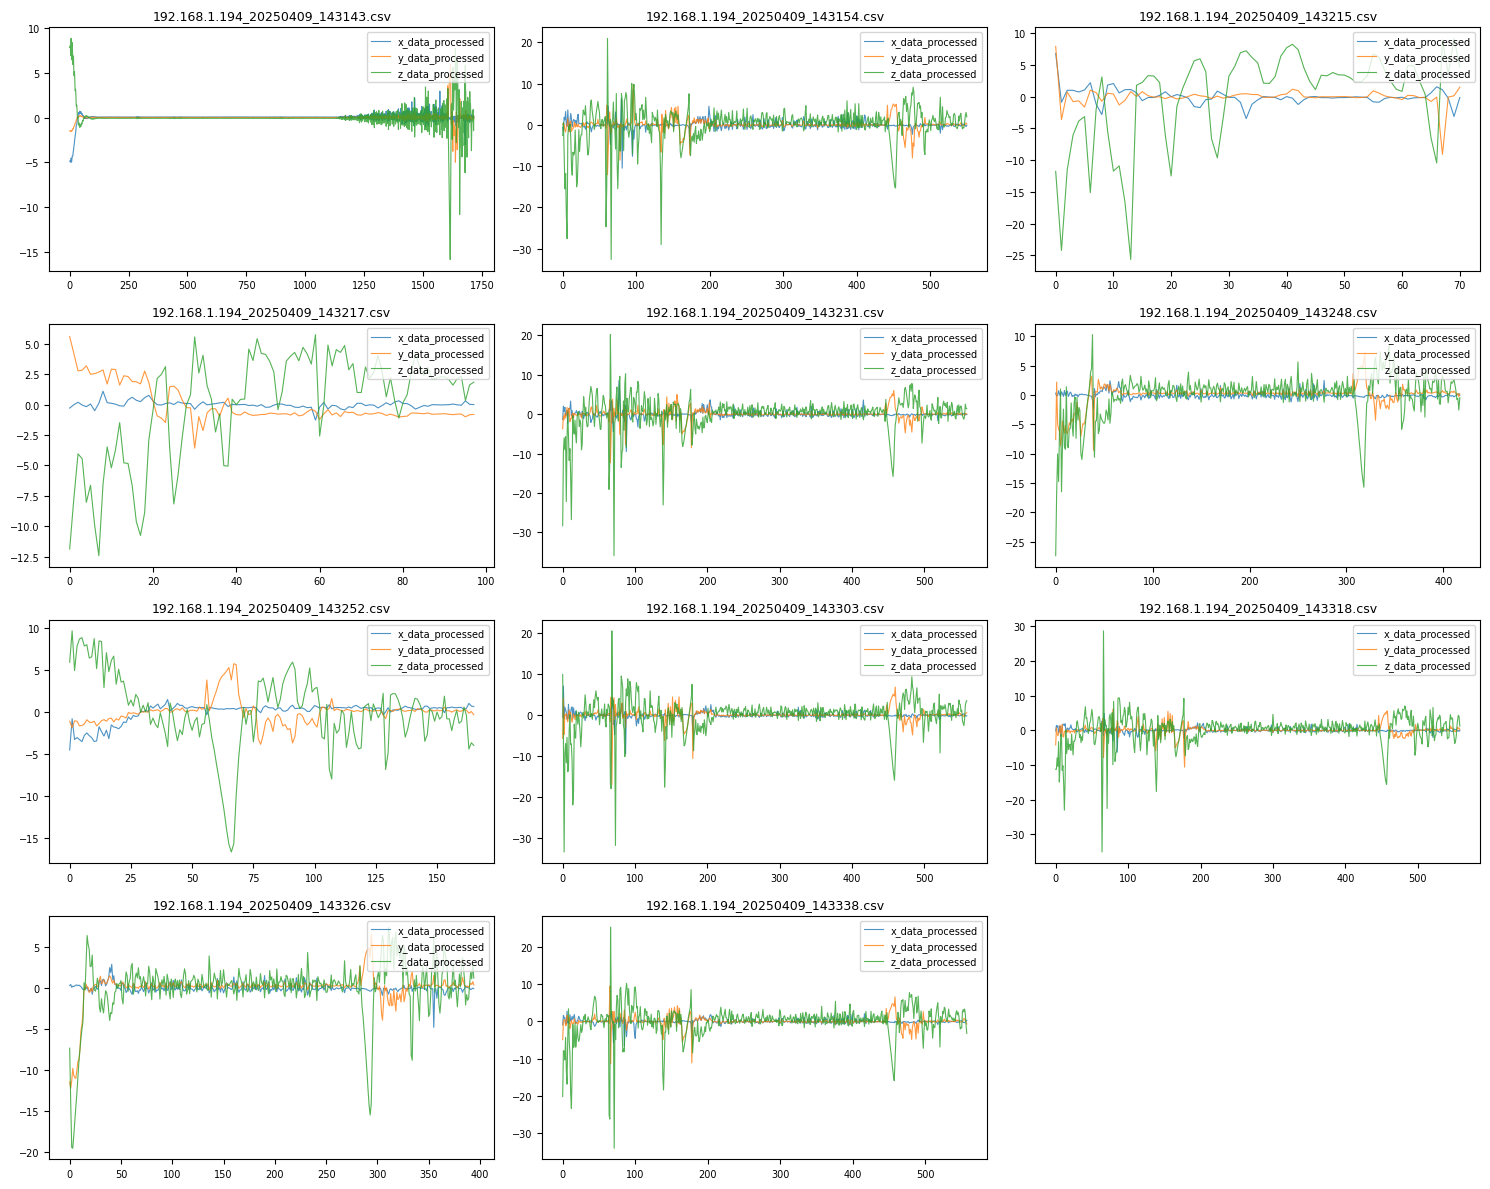

In [20]:
arquivos_realinhamento_esq = glob.glob("C:/Users/Raiza/Downloads/material_raiza/material_raiza/experimento_09_04_25_LLK/Realinhamento_esquerda_em_funcionamento/*.csv")
lista_df_realinhamento_esq = []
for arquivo in arquivos_realinhamento_esq:
    df = pd.read_csv(arquivo)
    df = configurar_colunas(df)
    df = preprocess_dataframe(df)
    lista_df_realinhamento_esq.append(df)

print(f"{len(lista_df_realinhamento_esq)} arquivos.")

plot_all_files(arquivos_realinhamento_esq, lista_df_realinhamento_esq)


7 arquivos.


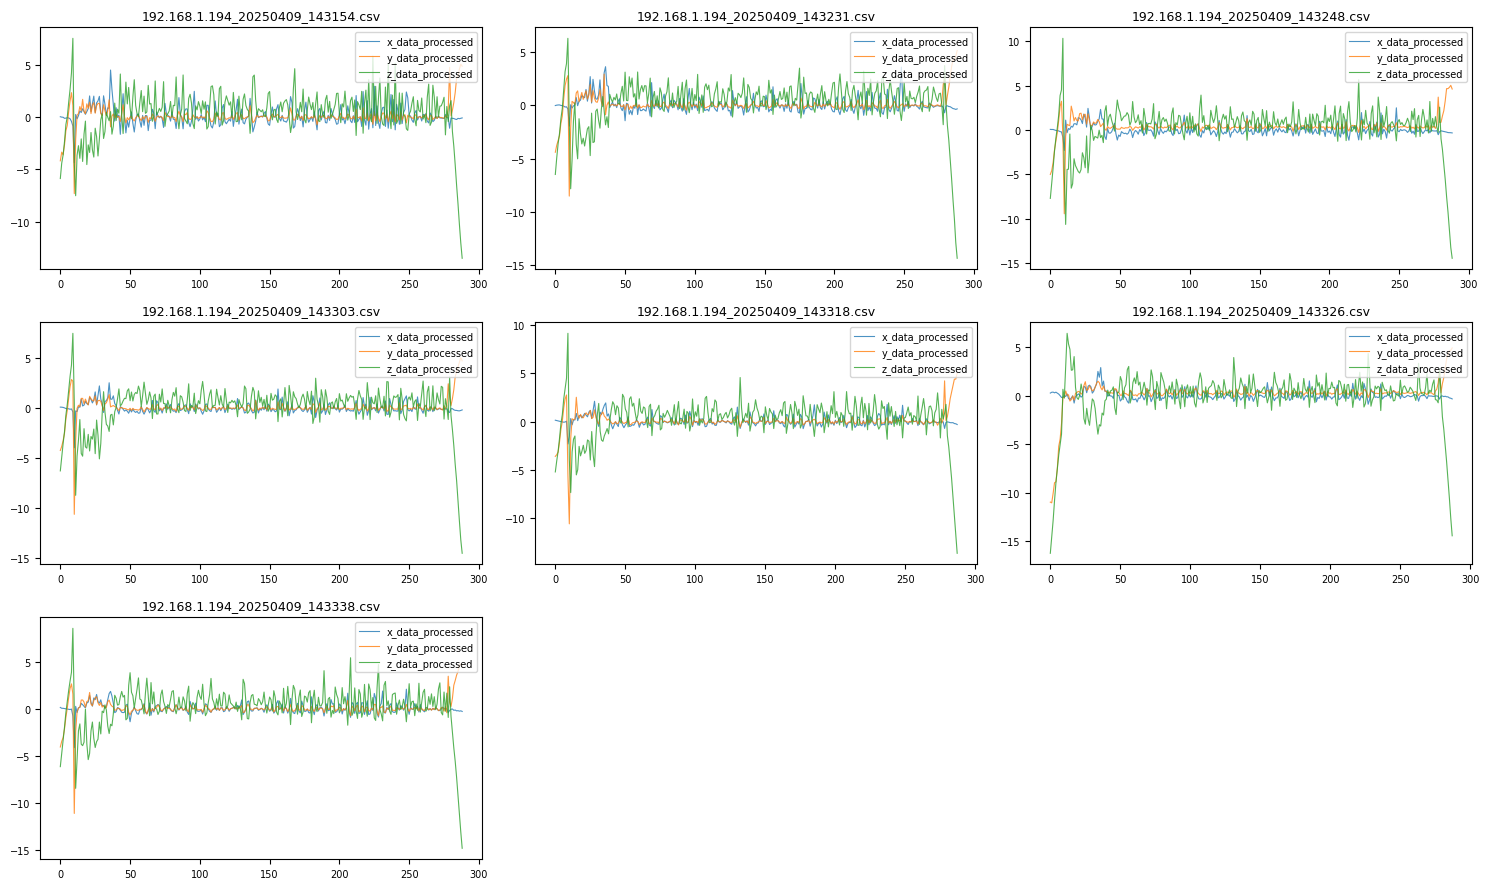

In [21]:
indices_remover = [0, 2, 3, 6]
lista_df_realinhamento_esq = [df for i, df in enumerate(lista_df_realinhamento_esq) if i not in indices_remover]
arquivos_realinhamento_esq = [arq for i, arq in enumerate(arquivos_realinhamento_esq) if i not in indices_remover]

print(f"{len(lista_df_realinhamento_esq)} arquivos.")

lista_df_realinhamento_esq = extract_z_positive_data(lista_df_realinhamento_esq)

df_realinhamento_esq = pd.concat(lista_df_realinhamento_esq, ignore_index=True)
plot_all_files(arquivos_realinhamento_esq, lista_df_realinhamento_esq)


In [22]:
for df in lista_df_realinhamento_esq:
    df[colunas_para_normalizar] = scaler.transform(df[colunas_para_normalizar])


8 arquivos.


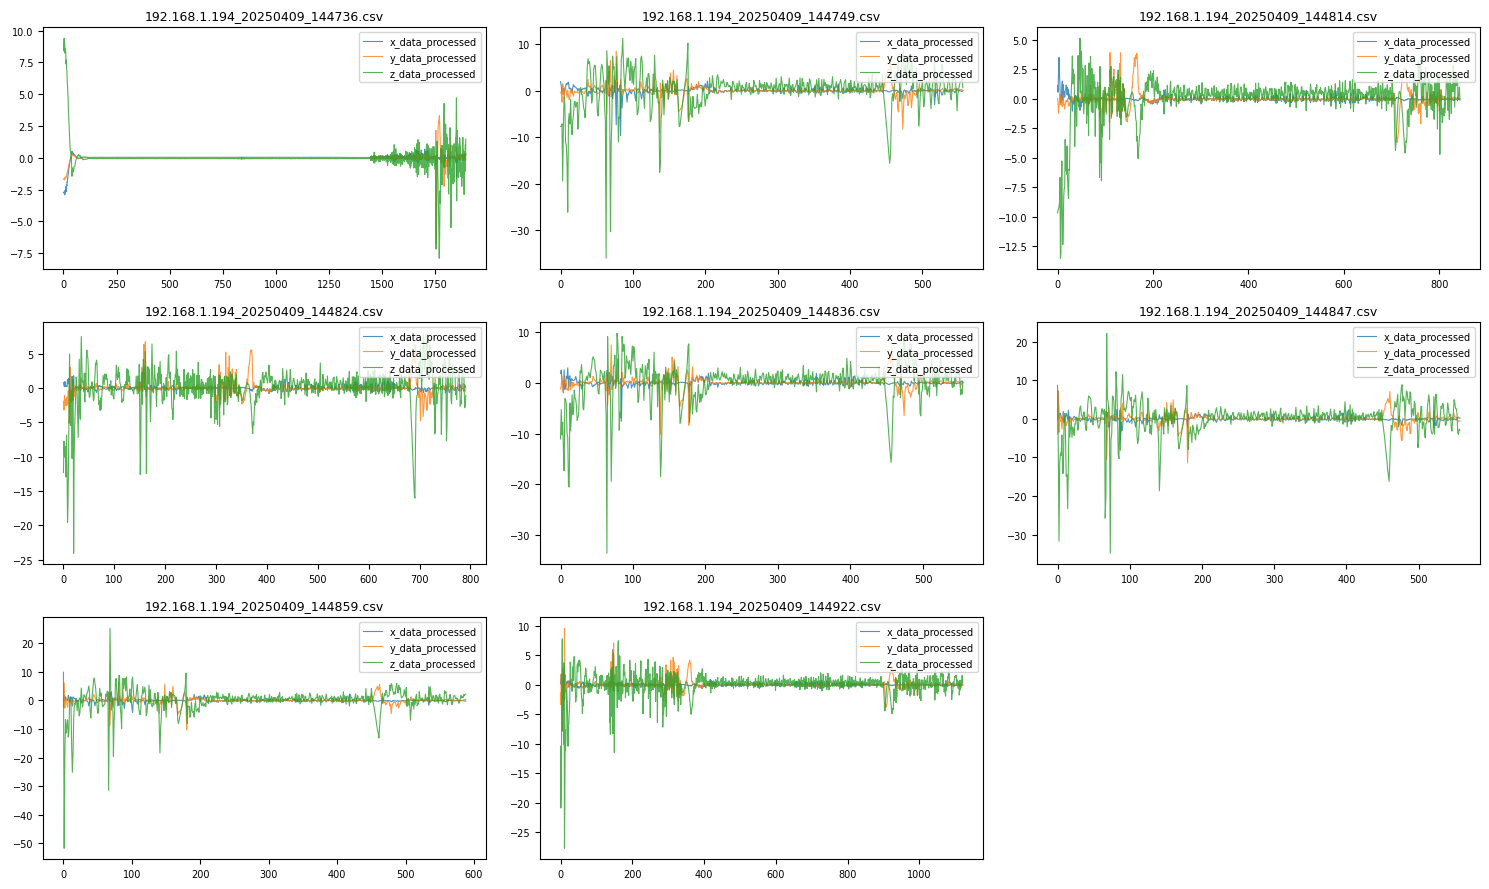

In [23]:
arquivos_variacao_vel = glob.glob("C:/Users/Raiza/Downloads/material_raiza/material_raiza/experimento_09_04_25_LLK/Variacao_velocidade_50Hz_25Hz/*.csv")
lista_df_variacao_vel = []
for arquivo in arquivos_variacao_vel:
    df = pd.read_csv(arquivo)
    df = configurar_colunas(df)
    df = preprocess_dataframe(df)
    lista_df_variacao_vel.append(df)

print(f"{len(lista_df_variacao_vel)} arquivos.")

plot_all_files(arquivos_variacao_vel, lista_df_variacao_vel)


7 arquivos.


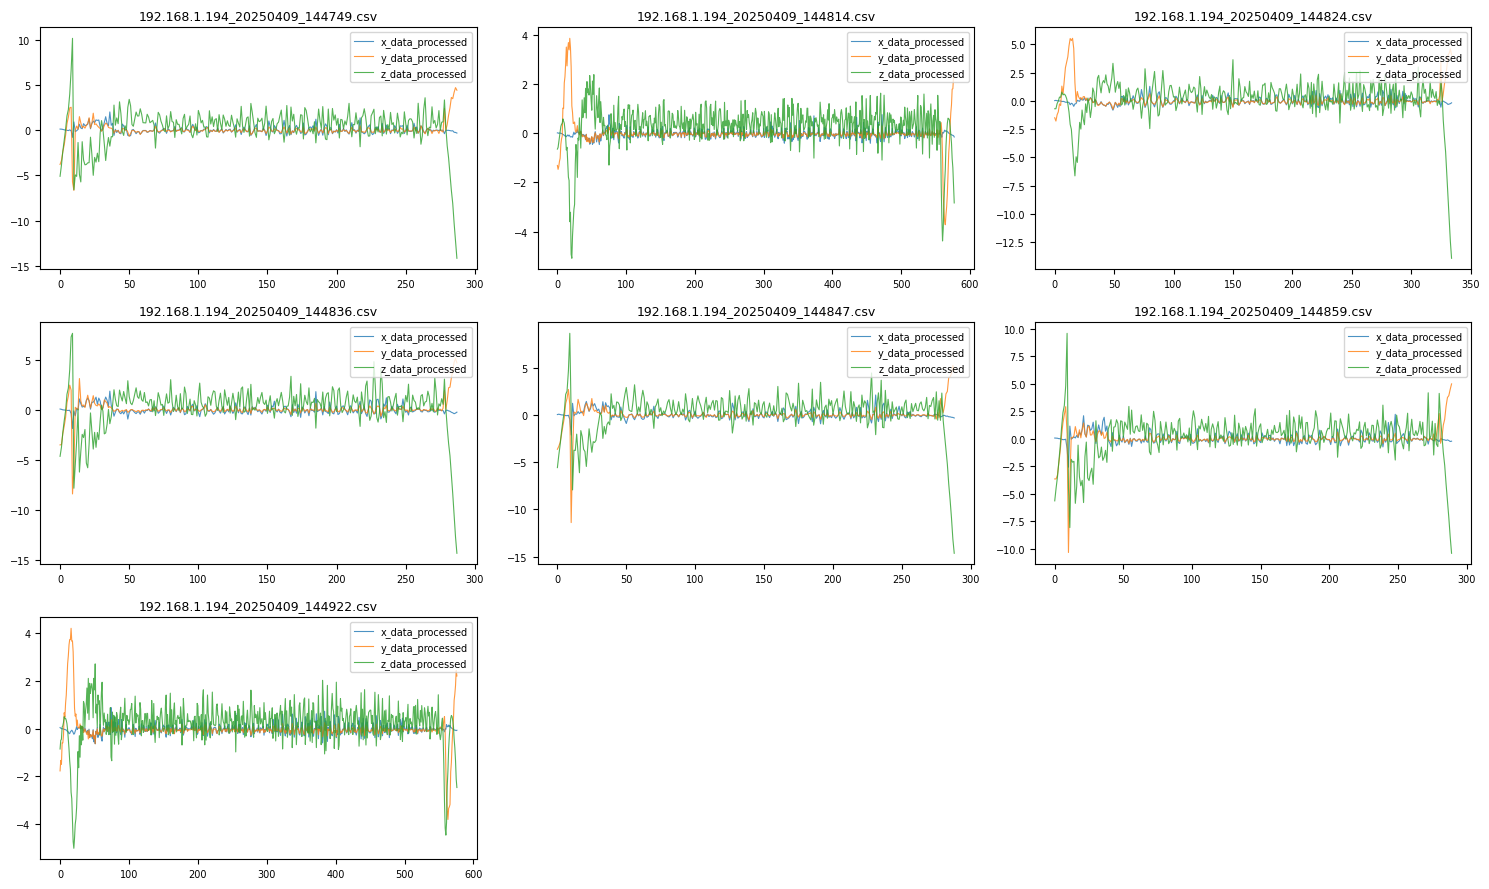

In [24]:
indices_remover = [0]
lista_df_variacao_vel = [df for i, df in enumerate(lista_df_variacao_vel) if i not in indices_remover]
arquivos_variacao_vel = [arq for i, arq in enumerate(arquivos_variacao_vel) if i not in indices_remover]

print(f"{len(lista_df_variacao_vel)} arquivos.")

lista_df_variacao_vel = extract_z_positive_data(lista_df_variacao_vel)

df_variacao_vel = pd.concat(lista_df_variacao_vel, ignore_index=True)
plot_all_files(arquivos_variacao_vel, lista_df_variacao_vel)


In [25]:
for df in lista_df_variacao_vel:
    df[colunas_para_normalizar] = scaler.transform(df[colunas_para_normalizar])


23 arquivos.


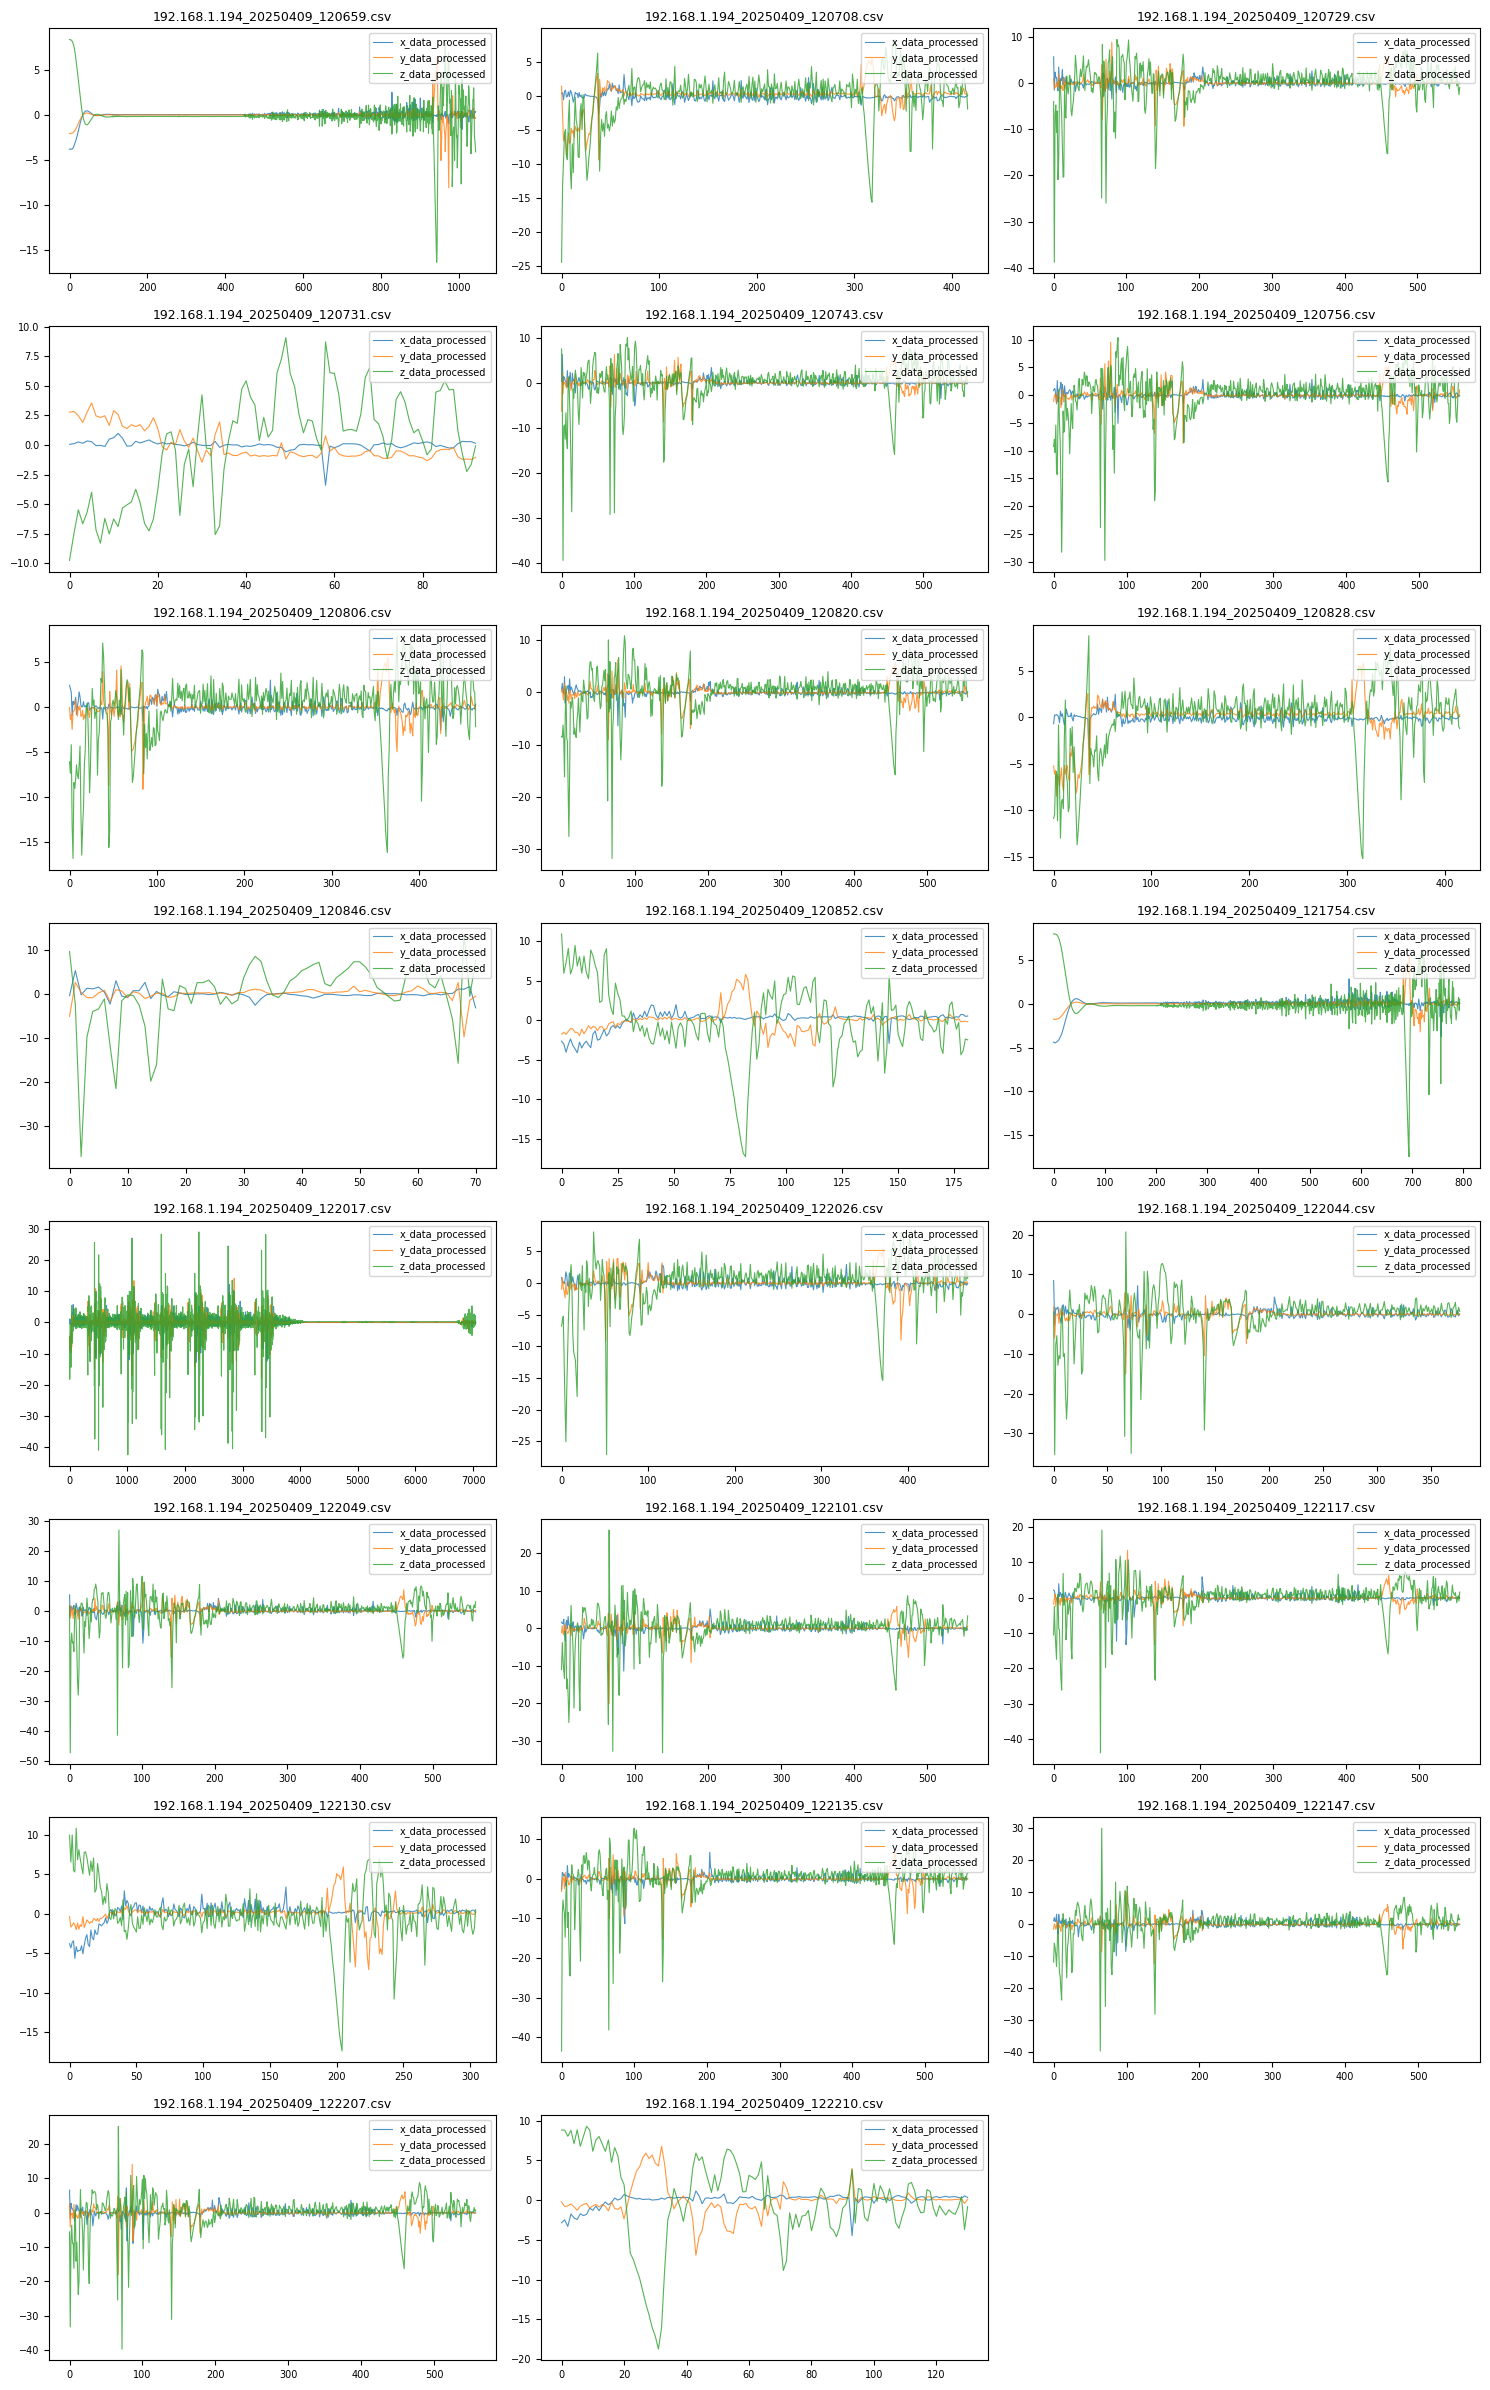

In [26]:
arquivos_positivo_realinhamento_esq = glob.glob("C:/Users/Raiza/Downloads/material_raiza/material_raiza/experimento_09_04_25_LLK/Movimento_postivo_x_realinhamento_esquerda_correia/*.csv")
lista_df_positivo_realinhamento_esq = []
for arquivo in arquivos_positivo_realinhamento_esq:
    df = pd.read_csv(arquivo)
    df = configurar_colunas(df)
    df = preprocess_dataframe(df)
    lista_df_positivo_realinhamento_esq.append(df)

print(f"{len(lista_df_positivo_realinhamento_esq)} arquivos.")

plot_all_files(arquivos_positivo_realinhamento_esq, lista_df_positivo_realinhamento_esq)


14 arquivos.


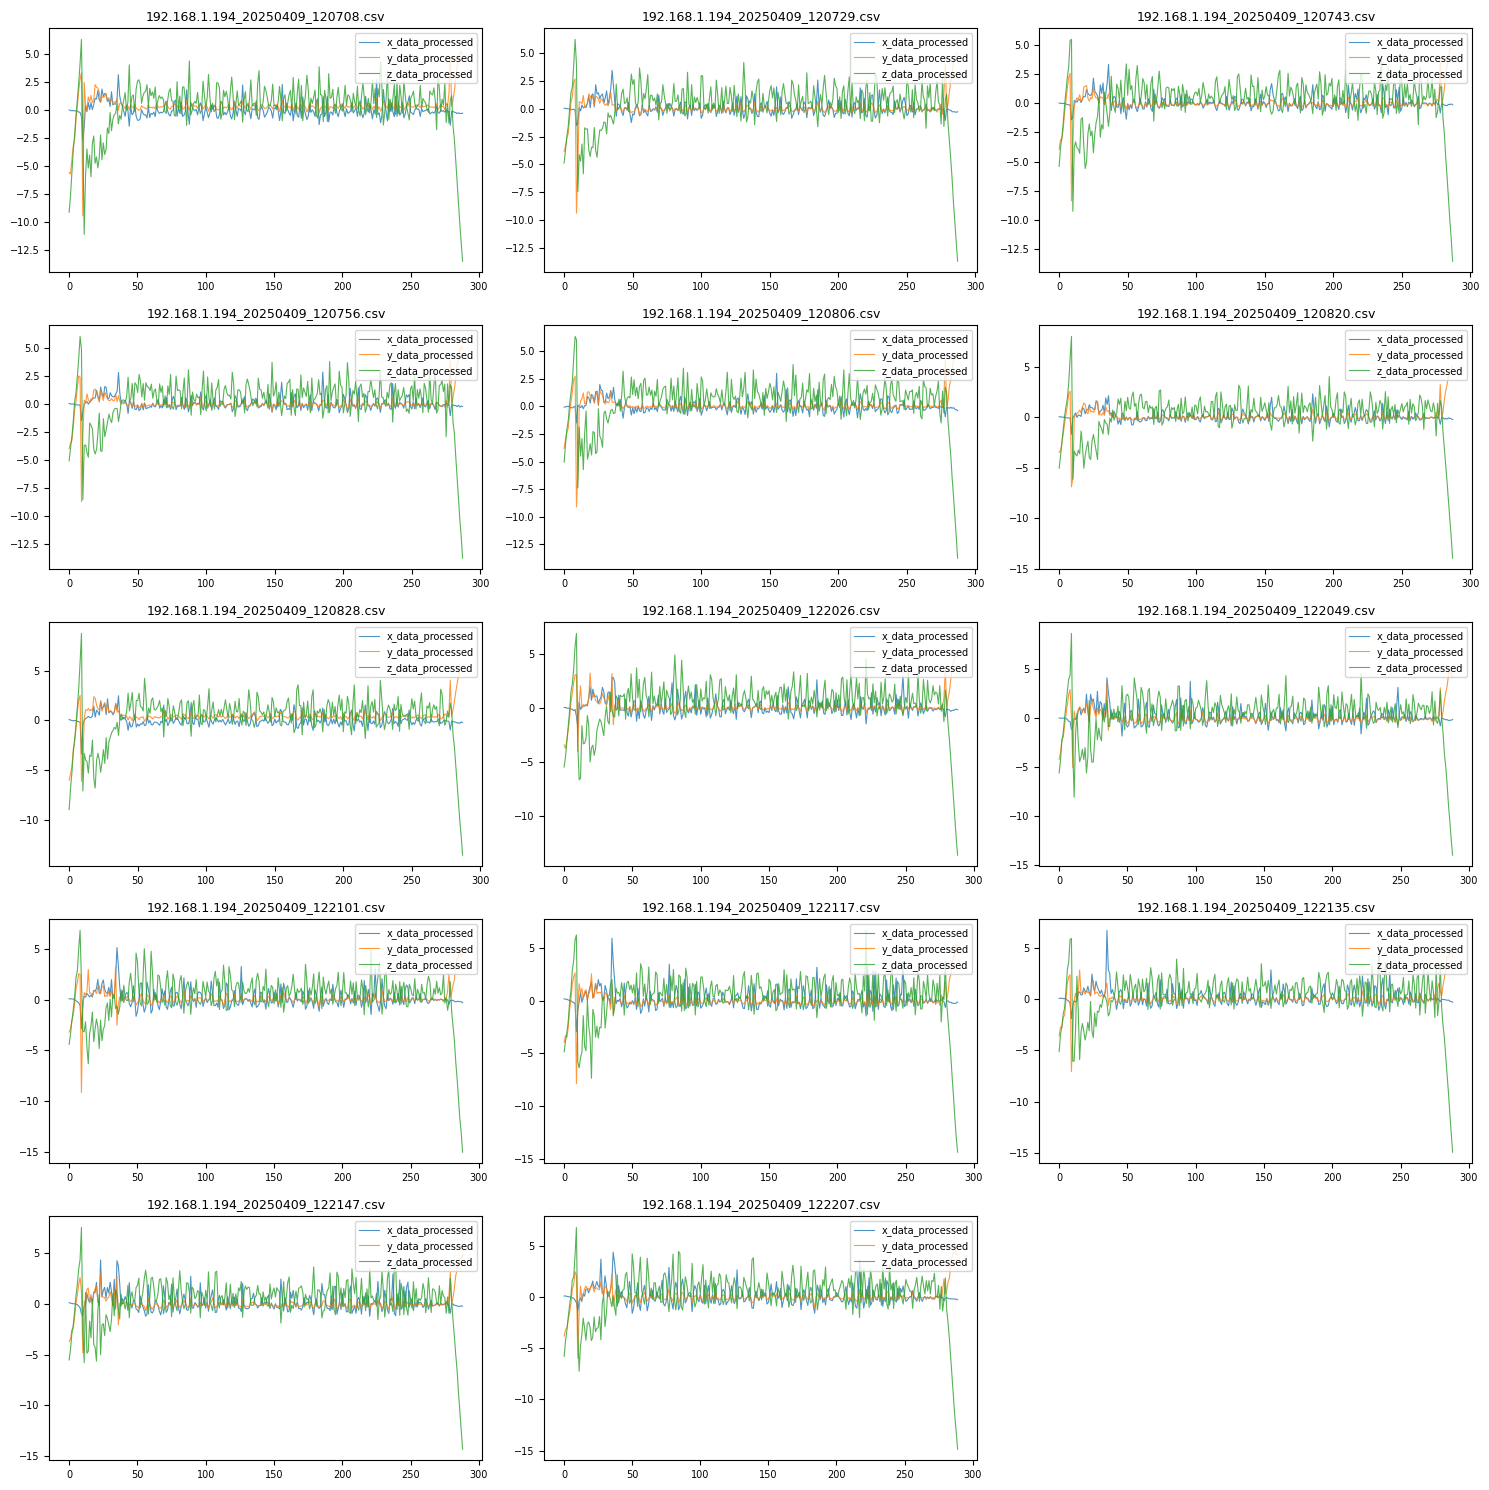

In [27]:
indices_remover = [0, 3, 9, 10, 11, 12, 14, 18, 22]
lista_df_positivo_realinhamento_esq = [df for i, df in enumerate(lista_df_positivo_realinhamento_esq) if i not in indices_remover]
arquivos_positivo_realinhamento_esq = [arq for i, arq in enumerate(arquivos_positivo_realinhamento_esq) if i not in indices_remover]

print(f"{len(lista_df_positivo_realinhamento_esq)} arquivos.")

lista_df_positivo_realinhamento_esq = extract_z_positive_data(lista_df_positivo_realinhamento_esq)

df_positivo_realinhamento_esq = pd.concat(lista_df_positivo_realinhamento_esq, ignore_index=True)
plot_all_files(arquivos_positivo_realinhamento_esq, lista_df_positivo_realinhamento_esq)


In [28]:
for df in lista_df_positivo_realinhamento_esq:
    df[colunas_para_normalizar] = scaler.transform(df[colunas_para_normalizar])


3 arquivos.


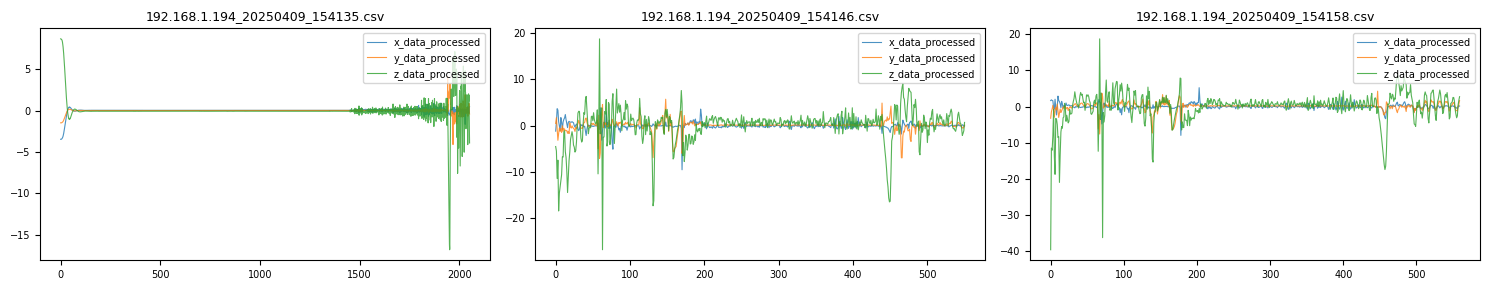

In [29]:
arquivos_rolete_travado = glob.glob("C:/Users/Raiza/Downloads/material_raiza/material_raiza/experimento_09_04_25_LLK/Rolete_travado/*.csv")
lista_df_rolete_travado = []
for arquivo in arquivos_rolete_travado:
    df = pd.read_csv(arquivo)
    df = configurar_colunas(df)
    df = preprocess_dataframe(df)
    lista_df_rolete_travado.append(df)

print(f"{len(lista_df_rolete_travado)} arquivos.")

plot_all_files(arquivos_rolete_travado, lista_df_rolete_travado)


2 arquivos.


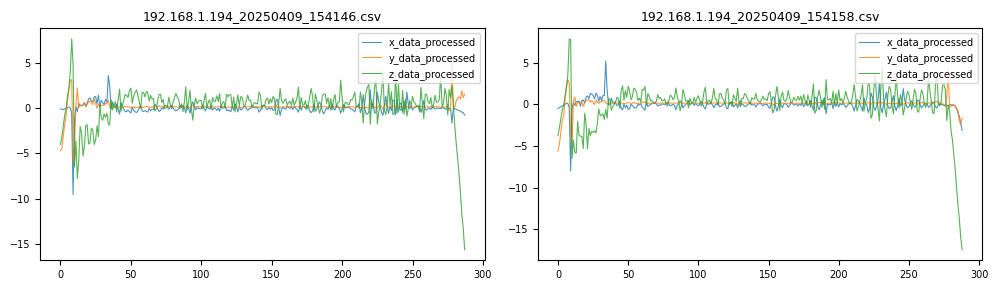

In [30]:
indices_remover = [0]
lista_df_rolete_travado = [df for i, df in enumerate(lista_df_rolete_travado) if i not in indices_remover]
arquivos_rolete_travado = [arq for i, arq in enumerate(arquivos_rolete_travado) if i not in indices_remover]

print(f"{len(lista_df_rolete_travado)} arquivos.")

lista_df_rolete_travado = extract_z_positive_data(lista_df_rolete_travado)

df_rolete_travado = pd.concat(lista_df_rolete_travado, ignore_index=True)
plot_all_files(arquivos_rolete_travado, lista_df_rolete_travado)


In [31]:
for df in lista_df_rolete_travado:
    df[colunas_para_normalizar] = scaler.transform(df[colunas_para_normalizar])


11 arquivos.


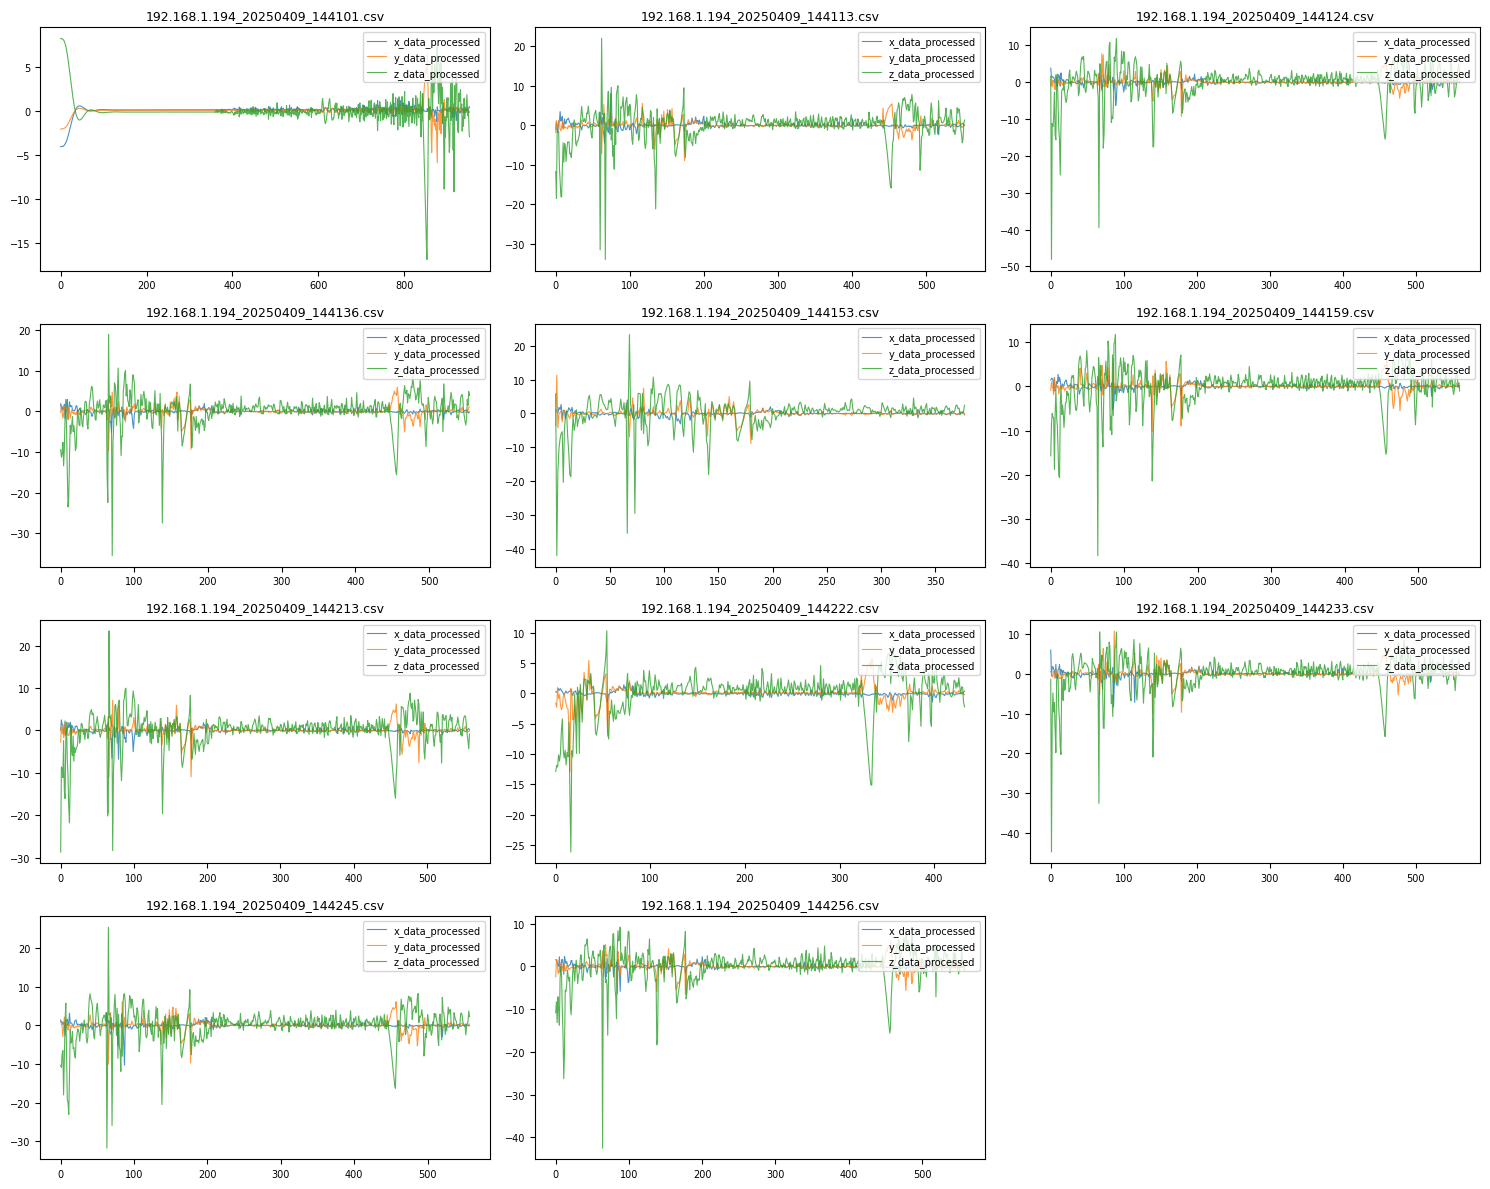

In [32]:
arquivos_sem_dois_roletes = glob.glob("C:/Users/Raiza/Downloads/material_raiza/material_raiza/experimento_09_04_25_LLK/Sem_dois_roletes/*.csv")
lista_df_sem_dois_roletes = []
for arquivo in arquivos_sem_dois_roletes:
    df = pd.read_csv(arquivo)
    df = configurar_colunas(df)
    df = preprocess_dataframe(df)
    lista_df_sem_dois_roletes.append(df)

print(f"{len(lista_df_sem_dois_roletes)} arquivos.")

plot_all_files(arquivos_sem_dois_roletes, lista_df_sem_dois_roletes)


9 arquivos.


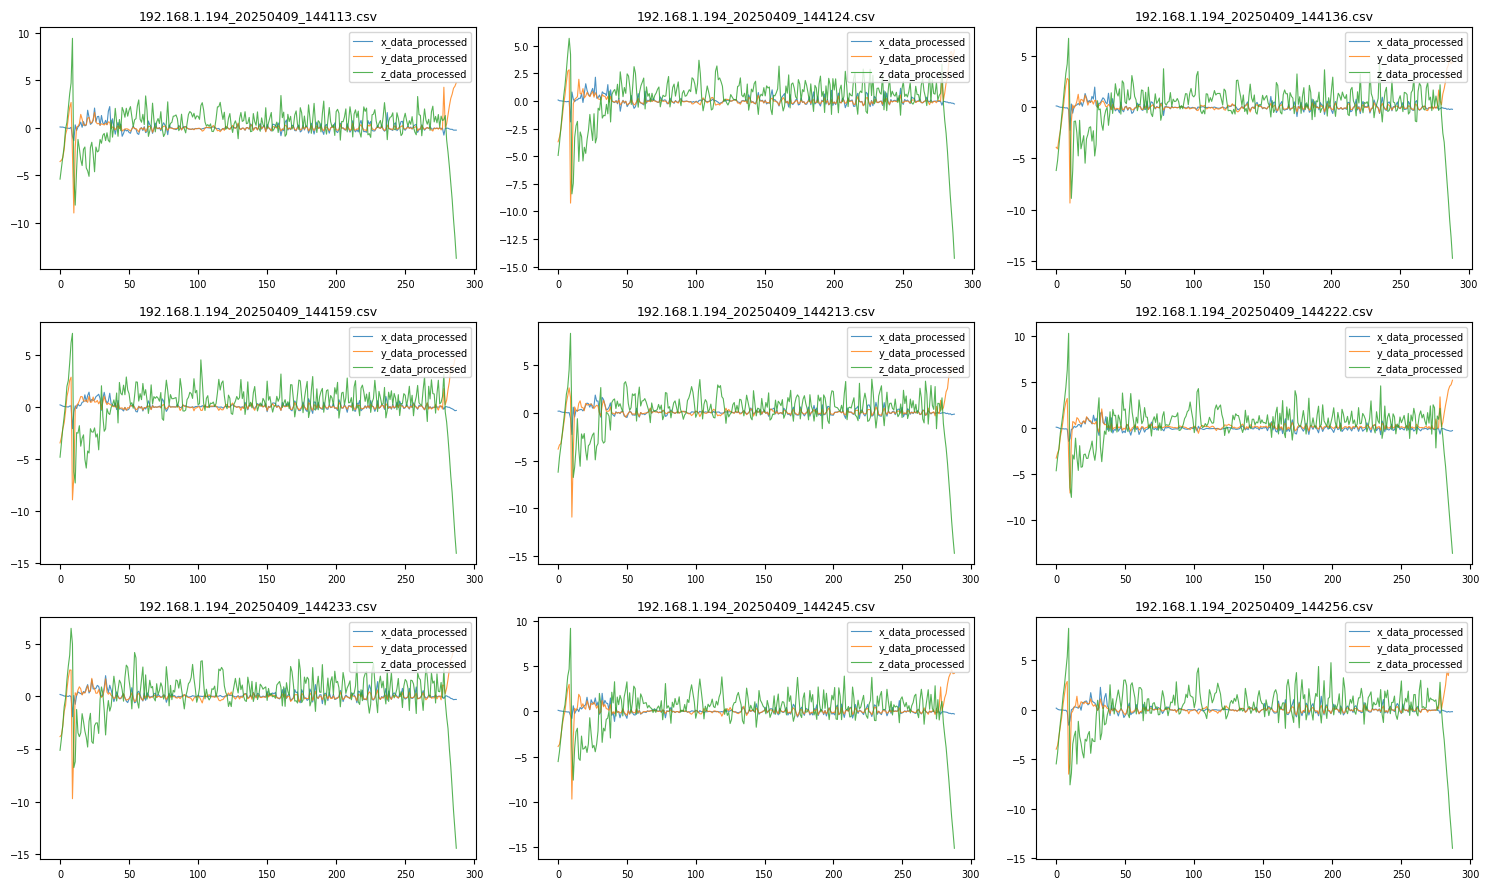

In [33]:
indices_remover = [0, 4]
lista_df_sem_dois_roletes = [df for i, df in enumerate(lista_df_sem_dois_roletes) if i not in indices_remover]
arquivos_sem_dois_roletes = [arq for i, arq in enumerate(arquivos_sem_dois_roletes) if i not in indices_remover]

print(f"{len(lista_df_sem_dois_roletes)} arquivos.")

lista_df_sem_dois_roletes = extract_z_positive_data(lista_df_sem_dois_roletes)

df_sem_dois_roletes = pd.concat(lista_df_sem_dois_roletes, ignore_index=True)
plot_all_files(arquivos_sem_dois_roletes, lista_df_sem_dois_roletes)


In [34]:
for df in lista_df_sem_dois_roletes:
    df[colunas_para_normalizar] = scaler.transform(df[colunas_para_normalizar])


In [35]:
sum = []
for arq in (lista_df_alinhado +
            lista_df_desalinhamento_dir +
            lista_df_realinhamento_dir +
            lista_df_realinhamento_esq +
            lista_df_variacao_vel +
            lista_df_positivo_realinhamento_esq +
            lista_df_rolete_travado +
            lista_df_sem_dois_roletes):
    sum.append(len(arq))
print(f"len media:{np.mean(sum)}")


len media:298.40625


## Extração de features e treinamento do modelo normal

In [36]:
def calcular_fft_metade_positiva(sinal, N, fs):
    """
    Calcula a metade positiva da FFT com zero-padding fixo de 256 pontos e normalização pelo
    tamanho original da janela.
    """
    N_pad = 256
    yf = scipy.fft.fft(sinal, n=N_pad)
    amplitude = np.abs(yf[0:N_pad//2]) * (2.0 / N)
    return amplitude

def extrair_features_de_uma_janela(janela_df, eixos, n_janela, fs):
    """Concatena as amplitudes espectrais dos eixos e suas médias para representar uma janela."""
    features = []

    for eixo in eixos:
        amps = calcular_fft_metade_positiva(janela_df[eixo].values, n_janela, fs)
        features.extend(amps)


    medias_espaciais = [np.mean(janela_df[e].values) for e in eixos]
    features.extend(medias_espaciais)

    return features

def processar_dataset_ml4qs(ficheiro_df, eixos, n_janela, step, fs):
    """
    Percorre um dataframe com janelas sobrepostas e retorna as features, os centros das
    janelas e o dataframe original.
    """
    if not all(col in ficheiro_df.columns for col in eixos):
        return None, None, None

    assinaturas_freq = []
    indices_centro = []

    for i in range(0, len(ficheiro_df) - n_janela, step):

        janela_df = ficheiro_df.iloc[i : i + n_janela]


        features_janela = extrair_features_de_uma_janela(janela_df, eixos, n_janela, fs)

        assinaturas_freq.append(features_janela)
        indices_centro.append(i + n_janela//2)

    return np.array(assinaturas_freq), indices_centro, ficheiro_df


In [37]:
def encontrar_cotovelo_kneedle(valores, start_index=1):
    """
    Estima o índice do cotovelo pela maior distância dos valores normalizados à diagonal de
    referência.
    """
    n_pontos = len(valores)
    if n_pontos < 2: return start_index
    x_norm = np.linspace(0, 1, n_pontos)
    y_norm = (valores - np.min(valores)) / (np.max(valores) - np.min(valores))
    y_norm = 1 - y_norm
    vec_reta = np.array([1, 1])
    vec_reta = vec_reta / np.linalg.norm(vec_reta)

    distancias = []
    for i in range(n_pontos):
        p = np.array([x_norm[i], y_norm[i]])
        proj = np.dot(p, vec_reta) * vec_reta
        dist = np.linalg.norm(p - proj)
        distancias.append(dist)
    return np.argmax(distancias) + start_index

def extrair_features_brutas(arquivos_lista, eixos, n_janela, step, fs):
    """Extrai e concatena as features de todas as coletas fornecidas."""
    X_bruto = []
    for arq in arquivos_lista:
        if len(arq) == 0: continue
        feats, _, _ = processar_dataset_ml4qs(arq, eixos, n_janela, step, fs)
        if feats is not None:
            X_bruto.extend(feats)
    return np.array(X_bruto)

def treinar_pca_com_cotovelo(X_scaled):
    """
    Escolhe o número de componentes pelo cotovelo da variância explicada e ajusta o PCA
    definitivo.
    """
    n_components_test = min(50, X_scaled.shape[1], X_scaled.shape[0])
    pca_temp = PCA(n_components=n_components_test)
    pca_temp.fit(X_scaled)

    n_pca_ideal = encontrar_cotovelo_kneedle(pca_temp.explained_variance_ratio_, start_index=1)

    pca_final = PCA(n_components=n_pca_ideal)
    X_pca = pca_final.fit_transform(X_scaled)
    return pca_final, X_pca, n_pca_ideal

def treinar_kmeans_com_cotovelo(X_pca):
    """
    Escolhe o número de clusters pelo cotovelo da inércia, ajusta o K-Means e define o
    limiar no percentil 99 das distâncias mínimas.
    """
    max_clusters = min(25, X_pca.shape[0])
    k_range = range(2, max_clusters)
    inertias = []

    for k in k_range:
        km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_pca)
        inertias.append(km.inertia_)

    melhor_k = encontrar_cotovelo_kneedle(inertias, start_index=2)

    kmeans_final = KMeans(n_clusters=melhor_k, random_state=42, n_init=10)
    kmeans_final.fit(X_pca)


    distancias = kmeans_final.transform(X_pca)
    min_distancias = np.min(distancias, axis=1)
    limiar = np.percentile(min_distancias, 99)

    return kmeans_final, limiar, melhor_k


In [38]:
todos_arquivos_alinhados = lista_df_alinhado
np.random.shuffle(todos_arquivos_alinhados)


X_bruto = extrair_features_brutas(todos_arquivos_alinhados, EIXOS, N_JANELA, STEP, FS)


scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_bruto)


pca, X_pca, n_pca_ideal = treinar_pca_com_cotovelo(X_scaled)
print(f"PCA treinado com {n_pca_ideal} componentes.")


kmeans, limiar_distancia, melhor_k = treinar_kmeans_com_cotovelo(X_pca)
print(f"K-Means treinado com {melhor_k} clusters. Limiar definido: {limiar_distancia:.4f}")


pacote_modelo = {
    'scaler': scaler, 'pca': pca, 'kmeans': kmeans, 'limiar': limiar_distancia,
    'fs': FS, 'n_janela': N_JANELA, 'step': STEP, 'eixos': EIXOS
}
joblib.dump(pacote_modelo, 'modelo_kmeans_final.pkl')
print("Treino concluído e pacote guardado com sucesso.")


PCA treinado com 5 componentes.
K-Means treinado com 6 clusters. Limiar definido: 10.6739
Treino concluído e pacote guardado com sucesso.


C:\Users\Raiza\AppData\Local\Temp\ipykernel_30800\442997080.py:13: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('tab20', n_clusters)


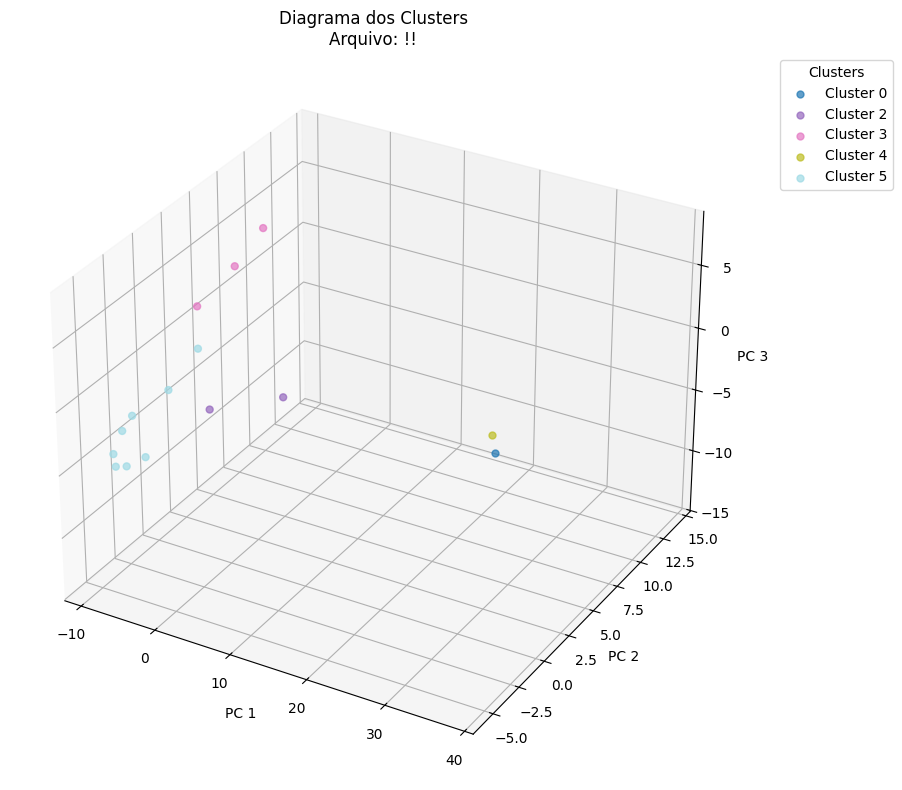

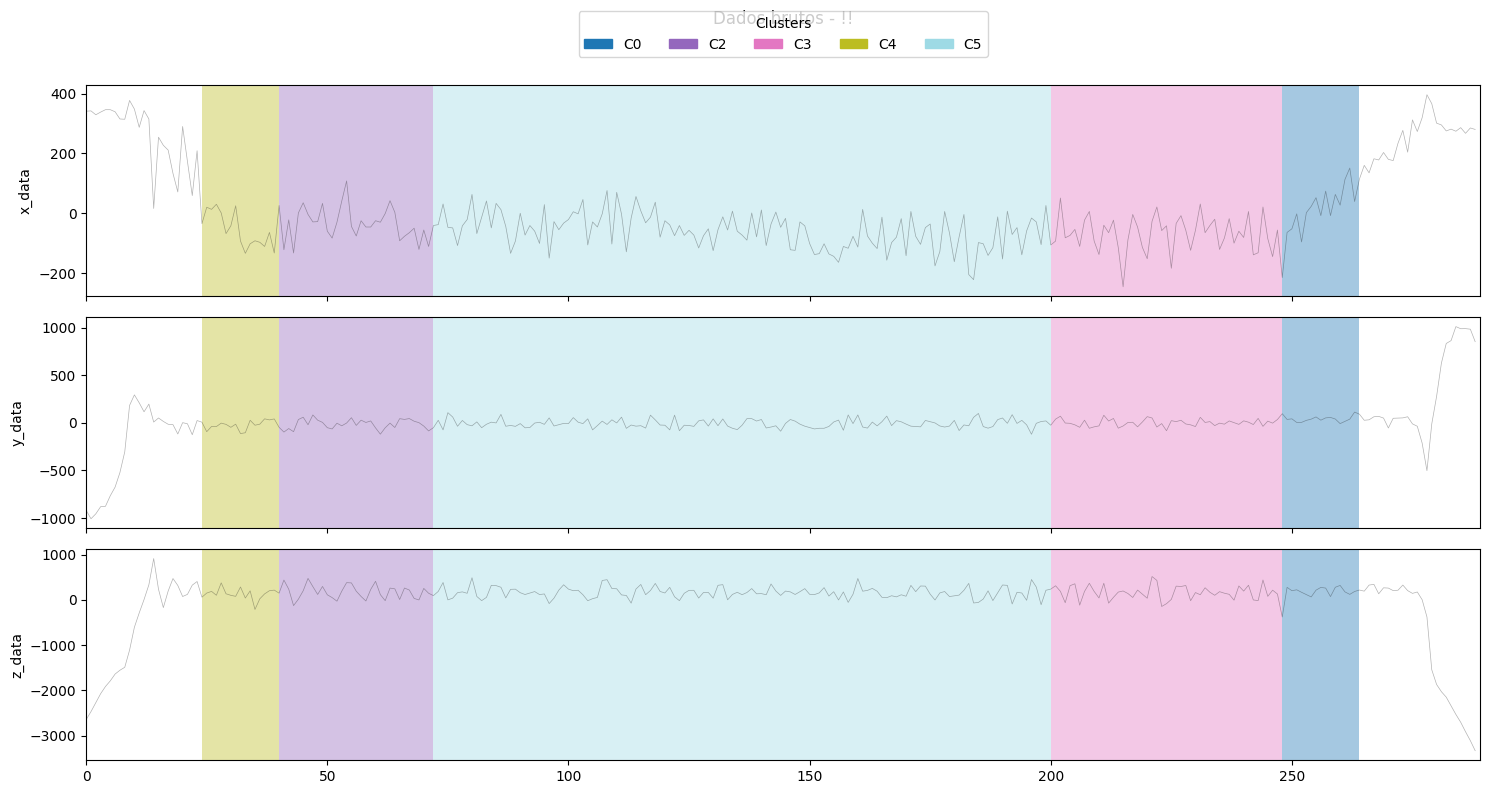

In [39]:
def visualizar_kmeans_clean(arquivo):
    """Projeta uma coleta no espaço PCA e mostra os clusters em 3D e sobre os sinais brutos."""
    feats, indices, df = processar_dataset_ml4qs(arquivo, EIXOS, N_JANELA, STEP, FS)
    if feats is None: return


    feats_scaled = scaler.transform(feats)
    feats_pca = pca.transform(feats_scaled)
    labels = kmeans.predict(feats_pca)

    unique_labels = np.unique(labels)
    n_clusters = kmeans.n_clusters
    cmap = cm.get_cmap('tab20', n_clusters)


    fig = plt.figure(figsize=(12, 8))
    ax = fig.add_subplot(111, projection='3d')

    for lbl in unique_labels:
        mask = (labels == lbl)
        ax.scatter(feats_pca[mask, 0], feats_pca[mask, 1], feats_pca[mask, 2],
                   color=cmap(lbl), s=25, alpha=0.7, label=f'Cluster {lbl}')

    ax.set_title(f"Diagrama dos Clusters\nArquivo: !!")

    ax.set_xlabel("PC 1")
    ax.set_ylabel("PC 2")
    ax.set_zlabel("PC 3")
    ax.legend(title="Clusters", bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()


    fig, axs = plt.subplots(3, 1, figsize=(15, 8), sharex=True)
    cols = ['x_data', 'y_data', 'z_data']

    for i, col in enumerate(cols):
        sinal = df[col].values - np.mean(df[col].values)
        axs[i].plot(df.index, sinal, color='black', alpha=0.3, lw=0.5)
        axs[i].set_ylabel(col)

        for lbl in unique_labels:
            indices_cluster = np.where(labels == lbl)[0]
            if len(indices_cluster) == 0: continue
            cor = cmap(lbl)
            for idx in indices_cluster:
                c = indices[idx]
                axs[i].axvspan(c - STEP//2, c + STEP//2, color=cor, alpha=0.4, lw=0)

    patches = [plt.Rectangle((0,0),1,1, color=cmap(l), label=f'C{l}') for l in unique_labels]
    axs[0].legend(handles=patches, loc='lower center', bbox_to_anchor=(0.5, 1.1),
                  ncol=min(len(unique_labels), 10), title="Clusters")

    axs[0].set_title(f"Dados brutos - !!", y=1.25)

    axs[2].set_xlim(0, len(df))
    plt.tight_layout()
    plt.show()

visualizar_kmeans_clean(todos_arquivos_alinhados[0])


## Detecção por distância aos centroides normais

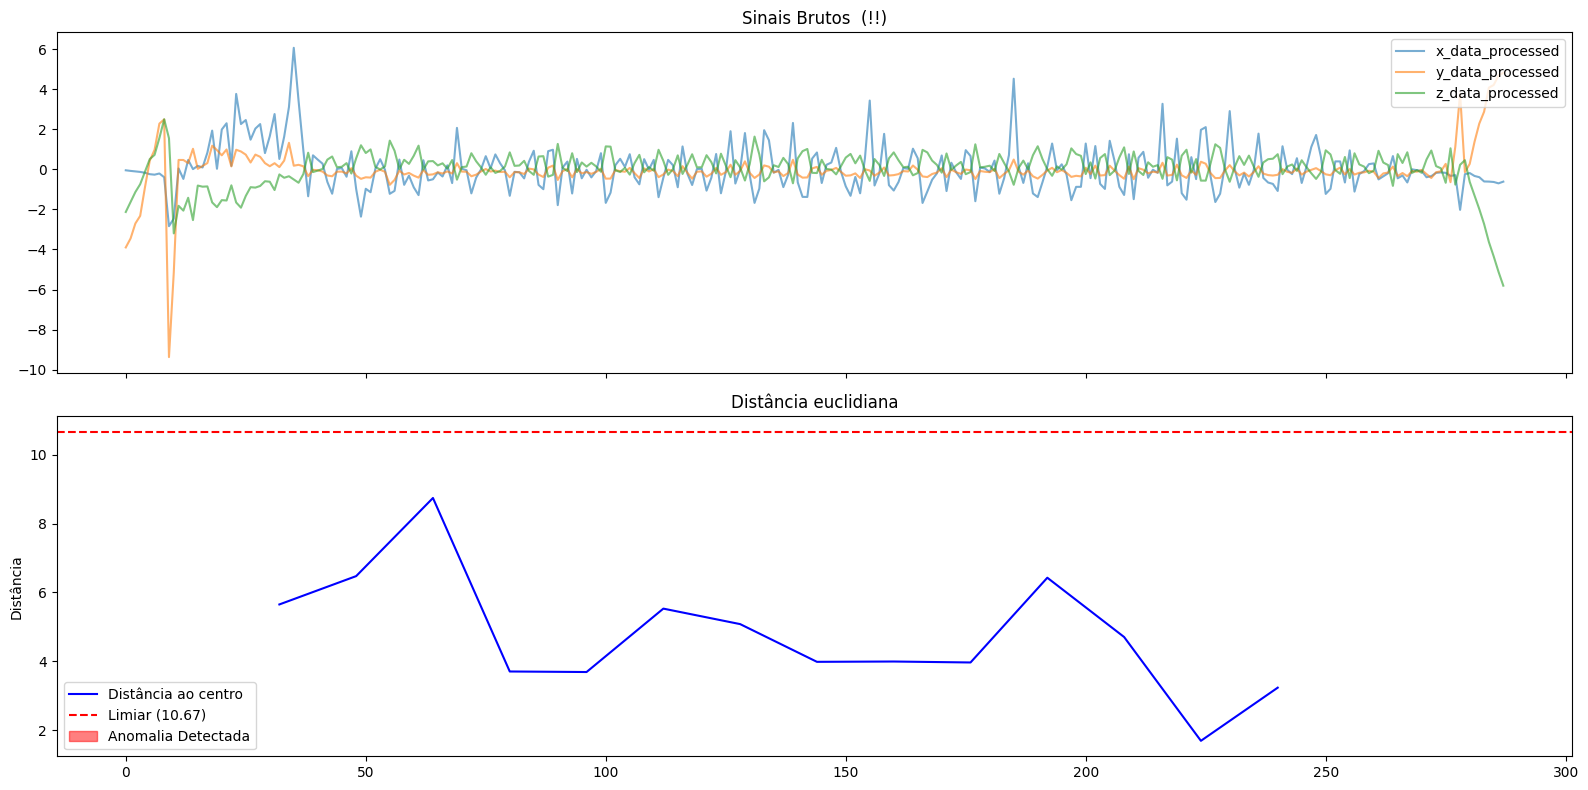

In [40]:
def diagnostico_anomalia_kmeans(arquivo):
    """
    Compara a distância de cada janela aos centroides normais com o limiar e destaca as
    detecções nos sinais.
    """
    razao = 1
    feats, indices, df = processar_dataset_ml4qs(arquivo, EIXOS, N_JANELA, STEP, FS)
    if feats is None: return
    feats_pca = pca.transform(scaler.transform(feats))

    distancias_todos = kmeans.transform(feats_pca)
    distancia_minima = np.min(distancias_todos, axis=1)
    is_anomaly = distancia_minima > limiar_distancia * razao

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 8), sharex=True)

    for col in EIXOS:
        ax1.plot(df.index, df[col], label=col, alpha=0.6)
    ax1.set_title(f"Sinais Brutos  (!!)")

    ax1.legend(loc='upper right')

    for k, anomalo in enumerate(is_anomaly):
        if anomalo:
            c = indices[k]
            ax1.axvspan(c-STEP//2, c+STEP//2, color='red', alpha=0.1, lw=0)
    ax2.plot(indices, distancia_minima, color='blue', label='Distância ao centro')
    ax2.axhline(limiar_distancia * razao, color='red', linestyle='--', label=f'Limiar ({limiar_distancia:.2f})')
    ax2.fill_between(indices, distancia_minima, limiar_distancia,
                     where=(distancia_minima > limiar_distancia * razao),
                     color='red', alpha=0.5, label='Anomalia Detectada')
    ax2.set_title("Distância euclidiana")
    ax2.set_ylabel("Distância")
    ax2.legend()
    plt.tight_layout()
    plt.show()

lista = lista_df_positivo_realinhamento_esq
if lista:
    diagnostico_anomalia_kmeans(lista[1])
else:
    print("Sem arquivos de anomalia")


## Detecção complementar por assinatura de anomalia

In [41]:
inertias = []
inertias_v2 = []
k_range = range(2, 25)
for k in k_range:
    kmeans_t = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_t.fit(X_pca)
    inertias.append(kmeans_t.inertia_)
inertias_v2.append
K_ANOMALIA = encontrar_cotovelo_kneedle(inertias, start_index=2)

arquivos_anomalia = lista_df_positivo_realinhamento_esq


def treinar_modelo_assinatura(lista_arquivos):
    """Treina um K-Means específico com as features das coletas escolhidas como anômalas."""
    todas_feats = []
    for arq in lista_arquivos:
        f, _, _ = processar_dataset_ml4qs(arq, EIXOS, N_JANELA, STEP, FS)
        if f is not None:
            todas_feats.append(f)
    X_an_treino = np.vstack(todas_feats)

    X_an_pca = pca.transform(scaler.transform(X_an_treino))
    km_an = KMeans(n_clusters=4, random_state=42, n_init=10)
    km_an.fit(X_an_pca)
    return km_an
kmeans_an_especifico = treinar_modelo_assinatura(arquivos_anomalia)


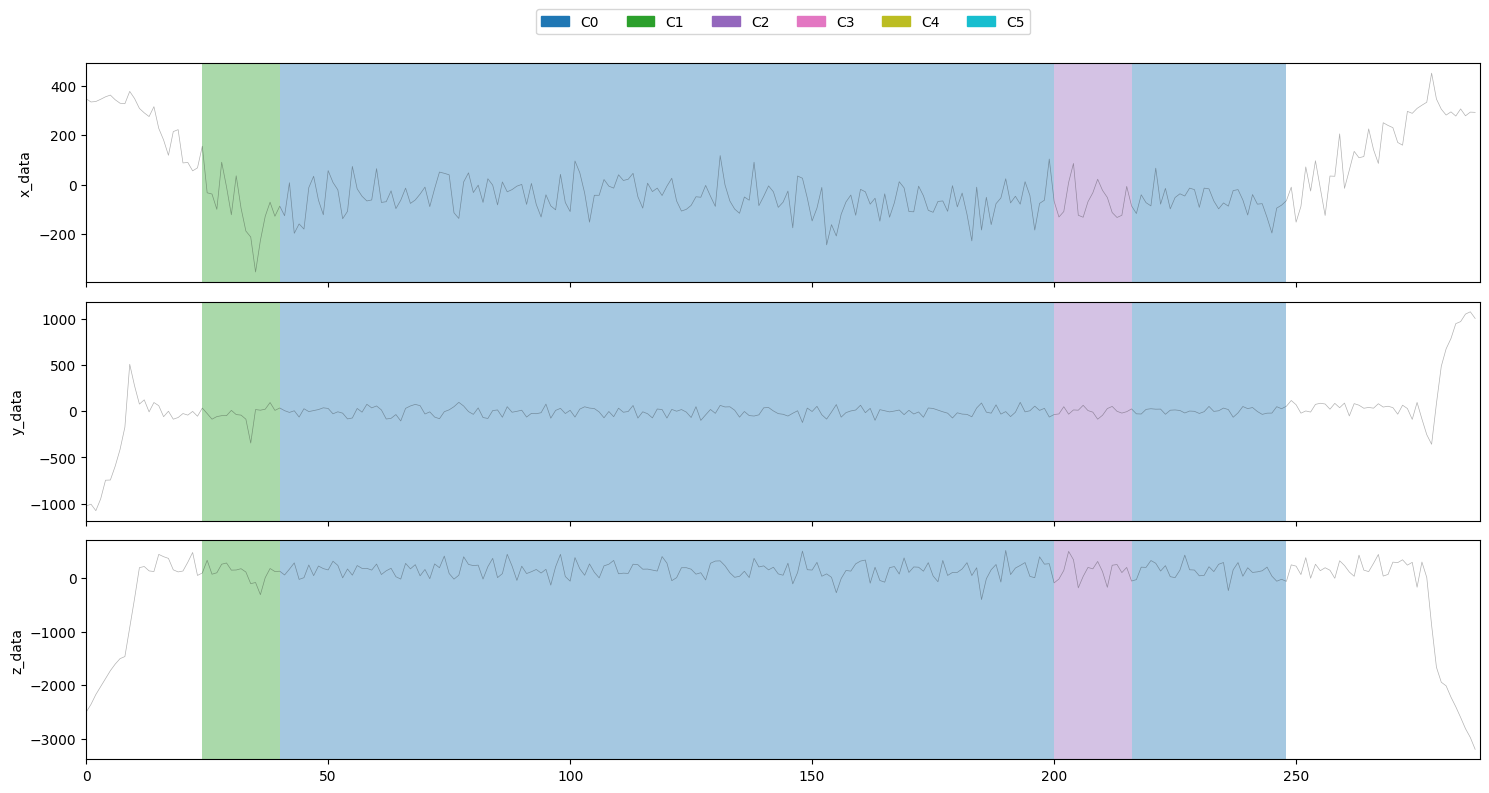

In [42]:
def visualizar_assinatura_anomalia(caminho_arquivo, kmeans_model):
    """Mostra sobre os sinais a distribuição temporal dos clusters do modelo de anomalia."""
    feats, indices, df = processar_dataset_ml4qs(caminho_arquivo, EIXOS, N_JANELA, STEP, FS)
    if feats is None: return

    feats_pca = pca.transform(scaler.transform(feats))
    labels = kmeans_model.predict(feats_pca)
    unique_labels = np.unique(labels)
    cmap = plt.get_cmap('tab10', K_ANOMALIA)

    fig, axs = plt.subplots(3, 1, figsize=(15, 8), sharex=True)

    cols = EIXOS_RAW
    for i, col in enumerate(cols):
        sinal = df[col].values - np.mean(df[col].values)
        axs[i].plot(df.index, sinal, color='black', alpha=0.3, lw=0.5)
        axs[i].set_ylabel(col)

        for lbl in unique_labels:
            indices_cluster = np.where(labels == lbl)[0]
            if len(indices_cluster) == 0: continue
            cor = cmap(lbl)
            for idx in indices_cluster:
                c = indices[idx]
                axs[i].axvspan(c - STEP//2, c + STEP//2, color=cor, alpha=0.4, lw=0)
    patches = [plt.Rectangle((0,0),1,1, color=cmap(l), label=f'C{l}') for l in range(K_ANOMALIA)]
    axs[0].legend(handles=patches, loc='lower center', bbox_to_anchor=(0.5, 1.1),
                  ncol=K_ANOMALIA)
    axs[2].set_xlim(0, len(df))
    plt.tight_layout()

    plt.show()


visualizar_assinatura_anomalia(arquivos_anomalia[3], kmeans_an_especifico)


In [43]:
def identificar_ids_anomalos(kmeans_orig, kmeans_an):
    """
    Identifica centroides do modelo de anomalia cuja distância mínima aos centroides normais
    supera o limiar global.
    """

    centros_normais = kmeans_orig.cluster_centers_
    centros_novos = kmeans_an.cluster_centers_
    ids_anomalos = []

    for i, centro_novo in enumerate(centros_novos):


        distancias = np.linalg.norm(centros_normais - centro_novo, axis=1)
        dist_minima = np.min(distancias)
        if dist_minima > limiar_distancia:
            ids_anomalos.append(i)
    return ids_anomalos

meus_ids_anomalia = identificar_ids_anomalos(kmeans, kmeans_an_especifico)
print(f"clusters identificados como anomalia: {meus_ids_anomalia}")
def testar_deteccao_automatica(lista_testes, kmeans_orig, kmeans_an, ids_an):
    """
    Conta janelas que estão distantes do modelo normal, pertencem a uma assinatura anômala e
    satisfazem simultaneamente as duas condições.
    """
    for arq in lista_testes:

        feats, _, _ = processar_dataset_ml4qs(arq, EIXOS, N_JANELA, STEP, FS)
        if feats is None: continue
        f_pca = pca.transform(scaler.transform(feats))

        dists_normais = kmeans_orig.transform(f_pca)
        esta_longe = np.min(dists_normais, axis=1) > limiar_distancia

        labels_an = kmeans_an.predict(f_pca)
        eh_assinatura = np.isin(labels_an, ids_an)
        confirmado = esta_longe & eh_assinatura

        print(f"distrib. de clusters: {dict(zip(*np.unique(labels_an, return_counts=True)))}")
        print(f"janelas com assinatura da anomalia: {np.sum(eh_assinatura)}")
        print(f"anomalia (longe do cluster normal e em um cluster de anomalia): {np.sum(confirmado)}")

testar_deteccao_automatica(arquivos_anomalia, kmeans, kmeans_an_especifico, meus_ids_anomalia)


clusters identificados como anomalia: [1, 3]
distrib. de clusters: {0: 9, 1: 2, 2: 4}
janelas com assinatura da anomalia: 2
anomalia (longe do cluster normal e em um cluster de anomalia): 1
distrib. de clusters: {0: 10, 1: 1, 2: 3}
janelas com assinatura da anomalia: 1
anomalia (longe do cluster normal e em um cluster de anomalia): 0
distrib. de clusters: {0: 11, 1: 1, 2: 2}
janelas com assinatura da anomalia: 1
anomalia (longe do cluster normal e em um cluster de anomalia): 0
distrib. de clusters: {0: 12, 1: 1, 2: 1}
janelas com assinatura da anomalia: 1
anomalia (longe do cluster normal e em um cluster de anomalia): 0
distrib. de clusters: {0: 13, 1: 1}
janelas com assinatura da anomalia: 1
anomalia (longe do cluster normal e em um cluster de anomalia): 0
distrib. de clusters: {0: 13, 1: 1}
janelas com assinatura da anomalia: 1
anomalia (longe do cluster normal e em um cluster de anomalia): 1
distrib. de clusters: {0: 12, 1: 1, 2: 1}
janelas com assinatura da anomalia: 1
anomalia (lo

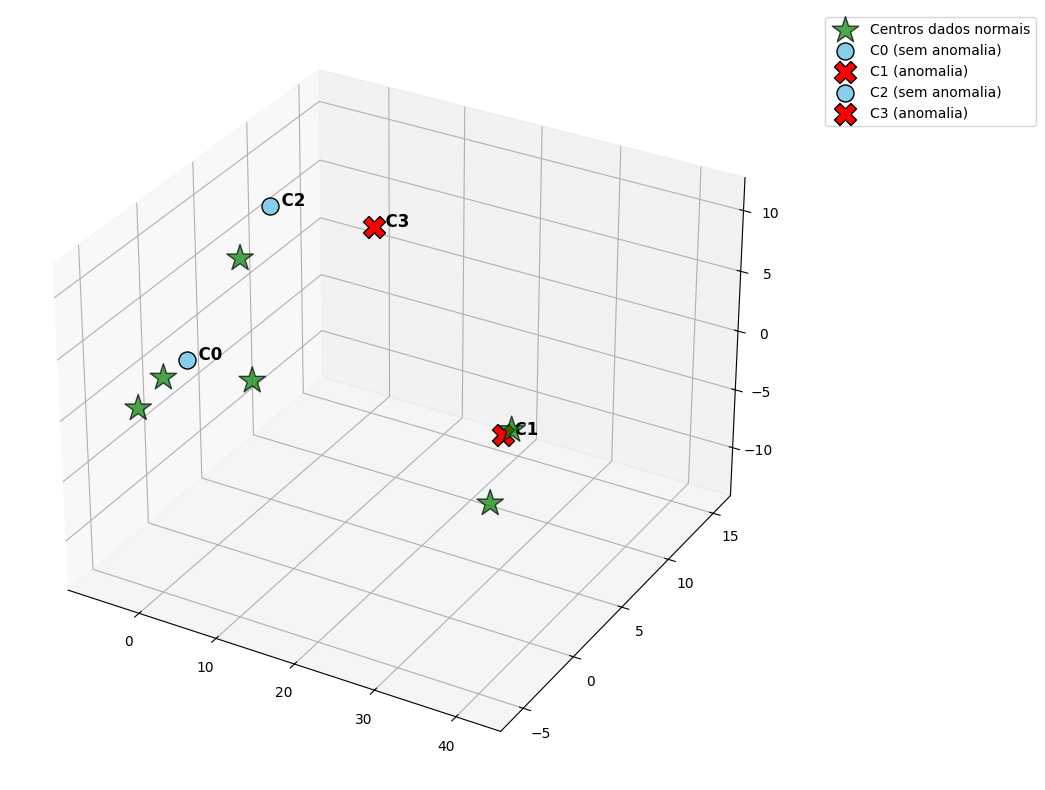

In [44]:
def visualizar_posicao_centroides(kmeans_orig, kmeans_an, ids_anomalos):
    """Compara em 3D os centroides normais e os centroides do modelo de anomalia."""
    centros_normais = kmeans_orig.cluster_centers_
    centros_anomalia = kmeans_an.cluster_centers_

    fig = plt.figure(figsize=(12, 8))
    ax = fig.add_subplot(111, projection='3d')


    ax.scatter(centros_normais[:, 0], centros_normais[:, 1], centros_normais[:, 2],
               s=400, c='green', marker='*', label='Centros dados normais', edgecolors='black', alpha=0.7)


    for i, centro in enumerate(centros_anomalia):

        if i in ids_anomalos:
            cor = 'red'
            label_text = f'C{i} (anomalia)'
            marker = 'X'
            s = 250
        else:
            cor = 'skyblue'
            label_text = f'C{i} (sem anomalia)'
            marker = 'o'
            s = 150

        ax.scatter(centro[0], centro[1], centro[2],
                   s=s, c=cor, marker=marker, label=label_text, edgecolors='black')
        ax.text(centro[0], centro[1], centro[2], f'  C{i}', size=12, weight='bold')
    handles, labels = ax.get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    ax.legend(by_label.values(), by_label.keys(), loc='upper left', bbox_to_anchor=(1.05, 1))

    plt.tight_layout()
    plt.show()
visualizar_posicao_centroides(kmeans, kmeans_an_especifico, meus_ids_anomalia)


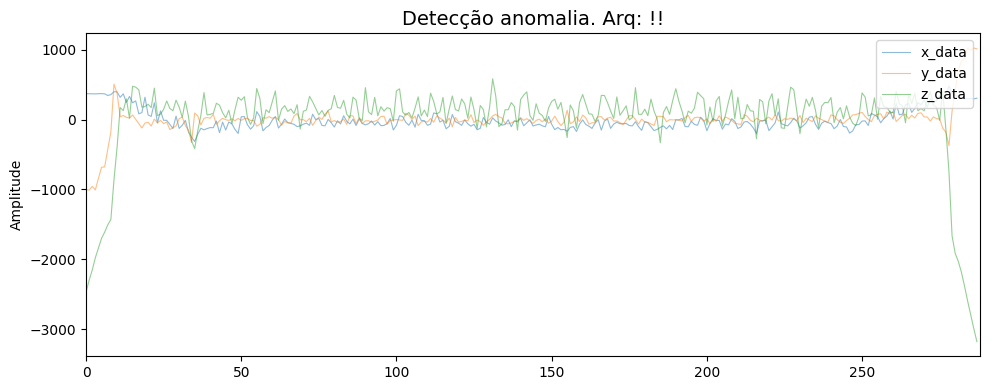

In [45]:
def visualizar_deteccao_confirmada(arquivo, kmeans_orig, kmeans_an, ids_an):
    """
    Destaca janelas confirmadas simultaneamente pela distância ao modelo normal e pela
    assinatura do modelo de anomalia.
    """

    feats, indices, df = processar_dataset_ml4qs(arquivo, EIXOS, N_JANELA, STEP, FS)
    if feats is None: return
    f_pca = pca.transform(scaler.transform(feats))


    dists_normais = kmeans_orig.transform(f_pca)
    esta_longe = np.min(dists_normais, axis=1) > limiar_distancia

    labels_an = kmeans_an.predict(f_pca)
    eh_assinatura = np.isin(labels_an, ids_an)

    confirmado = esta_longe & eh_assinatura
    indices_confirmados = np.where(confirmado)[0]

    fig, ax = plt.subplots(figsize=(10, 4))
    cols = ['x_data', 'y_data', 'z_data']
    cores_eixos = ['#1f77b4', '#ff7f0e', '#2ca02c']

    for i, col in enumerate(cols):

        sinal = df[col].values - np.mean(df[col].values)
        ax.plot(df.index, sinal, color=cores_eixos[i], alpha=0.5, lw=0.8, label=col)


        primeiro_span = True
        for idx in indices_confirmados:
            centro_janela = indices[idx]
            if i == 0 and primeiro_span:
                ax.axvspan(centro_janela - STEP//2, centro_janela + STEP//2,
                           color='red', alpha=0.3, lw=0, label='Anomalia')
                primeiro_span = False
            else:
                ax.axvspan(centro_janela - STEP//2, centro_janela + STEP//2,
                           color='red', alpha=0.3, lw=0)

    ax.set_ylabel("Amplitude")
    ax.set_title(f"Detecção anomalia. Arq: !!", fontsize=14)
    ax.set_xlim(0, len(df))
    ax.legend(loc='upper right')

    plt.tight_layout()
    plt.show()


visualizar_deteccao_confirmada(arquivos_anomalia[1], kmeans, kmeans_an_especifico, meus_ids_anomalia)


## Validação

In [46]:
def validar_deteccoes_kmeans(lista_arquivos, tipo='anomalia', inicio_correto=20, fim_correto=120):
    """
    Avalia arquivos normais ou anômalos pela presença e posição das detecções. Para
    anomalias, o intervalo informado representa a região considerada correta.
    """

    apenas_correto = 0
    correto_e_incorreto = 0
    apenas_incorreto = 0
    nenhuma_deteccao = 0


    falso_positivo = 0
    verdadeiro_negativo = 0

    arquivos_validos = 0

    for arq in lista_arquivos:

        feats, indices, df = processar_dataset_ml4qs(arq, EIXOS, N_JANELA, STEP, FS)


        if feats is None or len(feats) == 0:
            continue

        arquivos_validos += 1


        feats_scaled = scaler.transform(feats)
        feats_pca = pca.transform(feats_scaled)


        distancias = kmeans.transform(feats_pca)
        min_dist = np.min(distancias, axis=1)


        deteccoes = min_dist > limiar_distancia


        has_correct = False
        has_incorrect = False
        has_any_detection = False


        for is_anomalia, idx in zip(deteccoes, indices):
            if is_anomalia:
                has_any_detection = True

                if inicio_correto <= idx <= fim_correto:
                    has_correct = True
                else:
                    has_incorrect = True


        if tipo == 'anomalia':
            if has_correct and not has_incorrect:
                apenas_correto += 1
            elif has_correct and has_incorrect:
                correto_e_incorreto += 1
            elif not has_correct and has_incorrect:
                apenas_incorreto += 1
            elif not has_correct and not has_incorrect:
                nenhuma_deteccao += 1
        elif tipo == 'normal':
            if has_any_detection:
                falso_positivo += 1
            else:
                verdadeiro_negativo += 1


    if tipo == 'anomalia':
        print(f"Dados com anomalias ({arquivos_validos} arquivos):")
        print(f"Intervalo: {inicio_correto} a {fim_correto}")
        print(f"\nDetecção apenas no local correto: {apenas_correto}")
        print(f"Detecção no local correto E incorreto: {correto_e_incorreto}")
        print(f"Detecção apenas no local incorreto: {apenas_incorreto}")
        print(f"Nenhuma detecção (Falso Negativo): {nenhuma_deteccao}")
    else:
        print(f"Dados normais ({arquivos_validos} arquivos):")
        print(f"\nNenhuma detecção: {verdadeiro_negativo}")
        print(f"Anomalia detectada (Falso Positivo): {falso_positivo}")
    print("\n")


In [47]:
lista_df_desalinhado = lista_df_positivo_realinhamento_esq + lista_df_realinhamento_dir + lista_df_desalinhamento_dir + lista_df_realinhamento_esq + lista_df_realinhamento_dir + lista_df_rolete_travado + lista_df_sem_dois_roletes + lista_df_variacao_vel
validar_deteccoes_kmeans(lista_df_desalinhado, tipo='anomalia', inicio_correto=30, fim_correto=70)


Dados com anomalias (66 arquivos):
Intervalo: 30 a 70

Detecção apenas no local correto: 31
Detecção no local correto E incorreto: 16
Detecção apenas no local incorreto: 1
Nenhuma detecção (Falso Negativo): 18




In [48]:
validar_deteccoes_kmeans(lista_df_alinhado, tipo='normal')


Dados normais (8 arquivos):

Nenhuma detecção: 6
Anomalia detectada (Falso Positivo): 2


